# MAP Matematica 6: Serie de Fourier truncada y FFT

**Primera celda: instalacion de librerias.** Ejecutela una vez; si ya estan instaladas no hace nada. Si se instala algo nuevo (por ejemplo `ipywidgets`), reinicie el kernel y ejecute el notebook desde el inicio.

In [61]:
# instalacion de todas las librerias necesarias en el Python del kernel actual
%pip install -q numpy matplotlib pillow scipy pandas scikit-image ipywidgets torch

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


# Parte A: Series de Fourier

## Objetivo
Representar funciones periodicas mediante una serie de fourier truncada y evaluar su aproximacion usando la integral cuadrada del error (ICE).

## Primera Funcion
la funcion f1(t) vale 1 cuando -1 < t < 1 y vale 0 en el resto del intervalo de -2 a 2

In [62]:
import numpy as np

T = 4
t = np.linspace(-2, 2, 9)

print(t)

[-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5  2. ]


In [63]:
f1 = np.where((t > -1) & (t < 1), 1, 0)

print(f1)

[0 0 0 1 1 1 0 0 0]


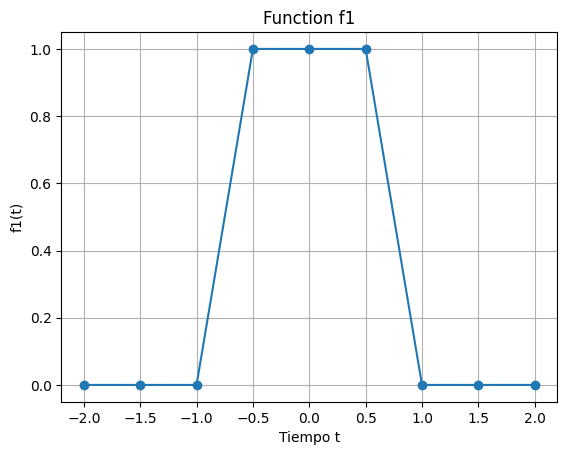

In [64]:
import matplotlib.pyplot as plt

plt.plot(t, f1, marker='o')
plt.xlabel('Tiempo t')
plt.ylabel('f1(t)')
plt.title('Function f1')
plt.grid(True)
plt.show()

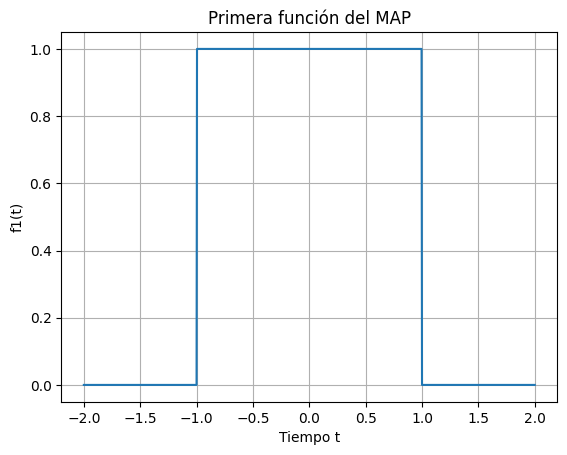

In [65]:
t = np.linspace(-2, 2, 1001)
f1 = np.where((t > -1) & (t < 1), 1, 0)

plt.plot(t, f1)
plt.xlabel("Tiempo t")
plt.ylabel("f1(t)")
plt.title("Primera función del MAP")
plt.grid(True)
plt.show()

In [66]:
def funcion_1(t):
    return np.where((t > -1) & (t < 1), 1, 0)

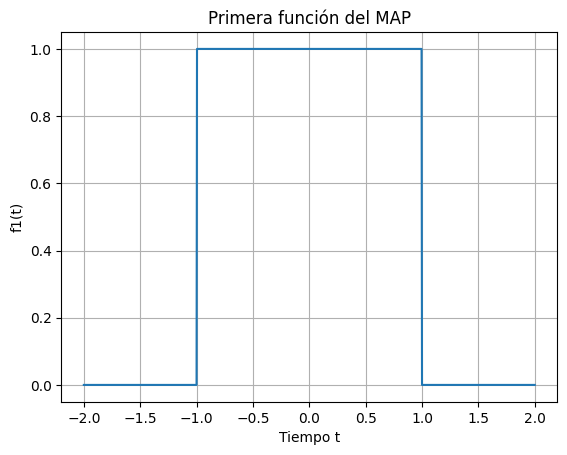

In [67]:
valores = funcion_1(t)

plt.plot(t, valores)
plt.xlabel("Tiempo t")
plt.ylabel("f1(t)")
plt.title("Primera función del MAP")
plt.grid(True)
plt.show()

In [68]:
def funcion_2(t):
    return np.where((t > -1) & (t < 1), t + 2, 0)

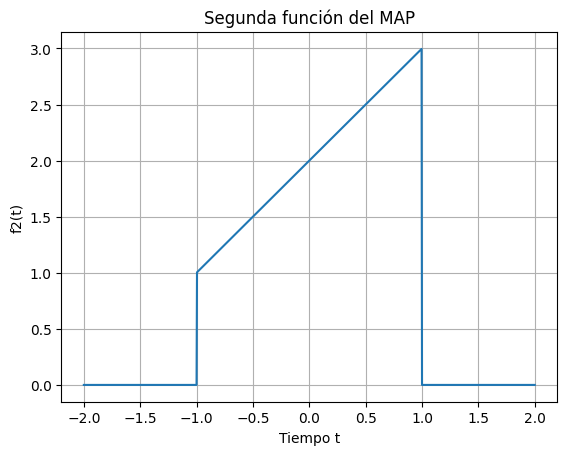

In [69]:
valores_2 = funcion_2(t)

plt.plot(t, valores_2)
plt.xlabel("Tiempo t")
plt.ylabel("f2(t)")
plt.title("Segunda función del MAP")
plt.grid(True)
plt.show()

In [70]:
def tiempo_periodico(t):
    return (t + 2) % 4 - 2

In [71]:
tiempos_prueba = np.array([0, 4, 8, -4, 4.5])

print(tiempo_periodico(tiempos_prueba))

[0.  0.  0.  0.  0.5]


In [72]:
def funcion_1_periodica(t):
    return funcion_1(tiempo_periodico(t))

def funcion_2_periodica(t):
    return funcion_2(tiempo_periodico(t))

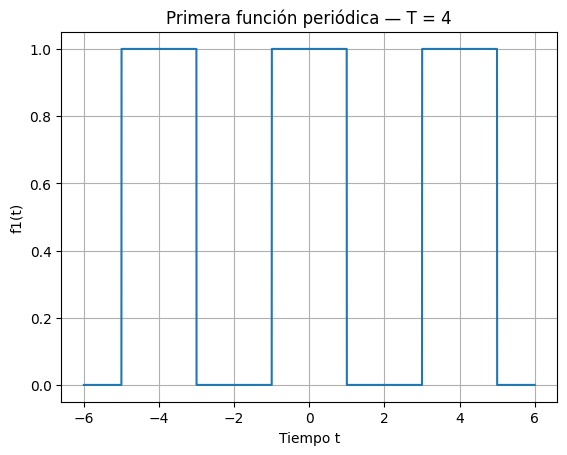

In [73]:
t_amplio = np.linspace(-6, 6, 3001)

plt.plot(t_amplio, funcion_1_periodica(t_amplio))
plt.xlabel("Tiempo t")
plt.ylabel("f1(t)")
plt.title("Primera función periódica — T = 4")
plt.grid(True)
plt.show()

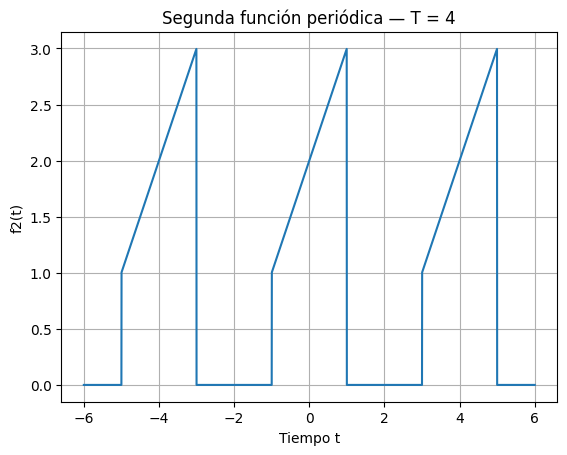

In [74]:
plt.plot(t_amplio, funcion_2_periodica(t_amplio))
plt.xlabel("Tiempo t")
plt.ylabel("f2(t)")
plt.title("Segunda función periódica — T = 4")
plt.grid(True)
plt.show()

In [75]:
omega_0 = 2 * np.pi / T

print("Período:", T)
print("Frecuencia angular fundamental:", omega_0)

Período: 4
Frecuencia angular fundamental: 1.5707963267948966


In [76]:
a0_f1 = 2 / T
a0_f2 = 4 / T

print("Valor promedio de f1:", a0_f1)
print("Valor promedio de f2:", a0_f2)

Valor promedio de f1: 0.5
Valor promedio de f2: 1.0


In [77]:
from scipy.integrate import quad

integral_f1, error_estimado = quad(funcion_1, -2, 2, points=[-1, 0, 1])

a0_f1 = integral_f1 / T

print("Integral de f1:", integral_f1)
print("Coeficiente a0 de f1:", a0_f1)
print("Error estimado de integración:", error_estimado)

Integral de f1: 2.0
Coeficiente a0 de f1: 0.5
Error estimado de integración: 2.220446049250313e-14


In [78]:
def calcular_a0(funcion):
    integral, error_estimado = quad(funcion, -2, 2, points=[-1, 0, 1])
    return integral / T

In [79]:
a0_f1 = calcular_a0(funcion_1)
a0_f2 = calcular_a0(funcion_2)

print("a0 de f1:", a0_f1)
print("a0 de f2:", a0_f2)

a0 de f1: 0.5
a0 de f2: 1.0


In [80]:
def calcular_an(funcion, n):
    def integrando(t):
        return funcion(t) * np.cos(n * omega_0 * t)

    integral, error_estimado = quad(integrando, -2, 2, points=[-1, 0, 1])

    return (2 / T) * integral

In [81]:
a1_f1 = calcular_an(funcion_1, 1)

print("a1 de f1:", a1_f1)

a1 de f1: 0.6366197723675813


In [82]:
def calcular_bn(funcion, n):
    def integrando(t):
        return funcion(t) * np.sin(n * omega_0 * t)

    integral, error_estimado = quad(integrando, -2, 2, points=[-1, 0, 1])

    return (2 / T) * integral

In [83]:
b1_f1 = calcular_bn(funcion_1, 1)
b1_f2 = calcular_bn(funcion_2, 1)

print("b1 de f1:", b1_f1)
print("b1 de f2:", b1_f2)

b1 de f1: 0.0
b1 de f2: 0.4052847345693508


In [84]:
def serie_fourier(funcion, tiempos, N):
    # Empezamos con el valor promedio en todos los tiempos.
    aproximacion = np.full_like(
        tiempos,
        calcular_a0(funcion),
        dtype=float
    )

    # Sumamos los armónicos desde 1 hasta N.
    for n in range(1, N + 1):
        an = calcular_an(funcion, n)
        bn = calcular_bn(funcion, n)

        aproximacion += (
            an * np.cos(n * omega_0 * tiempos)
            + bn * np.sin(n * omega_0 * tiempos)
        )

    return aproximacion

In [85]:
def calcular_energia(funcion):
    def integrando(t):
        return funcion(t) ** 2

    energia, error_estimado = quad(integrando, -2, 2, points=[-1, 0, 1])

    return energia

In [86]:
energia_f1 = calcular_energia(funcion_1)
energia_f2 = calcular_energia(funcion_2)

print("Energía de f1:", energia_f1)
print("Energía de f2:", energia_f2)

Energía de f1: 2.0
Energía de f2: 8.666666666666666


In [87]:
def calcular_ice(funcion, N):
    energia = calcular_energia(funcion)
    a0 = calcular_a0(funcion)

    suma_coeficientes = 0.0

    for n in range(1, N + 1):
        an = calcular_an(funcion, n)
        bn = calcular_bn(funcion, n)

        suma_coeficientes += an**2 + bn**2

    energia_aproximacion = (T * a0**2 + (T / 2) * suma_coeficientes)

    return energia - energia_aproximacion

## Interfaz Para la parte A:

Aqui se desarolla una interfaz interactiva para que el usuario tenga la opcion de visualizar cualquiera de las dos funciones (f1 o f2)
Por lo que tendra un menu en donde pueda seleccionar
- Menu para elegir su funcion
- Control para mostrar entre 1 y 5 periodos
- Grafica que se actualiza al cambiar los controles
- Periodo y frecuencia angular
- Opcion para activar o quitar la cuadricula

In [88]:
def encontrar_n(funcion, tolerancia=0.02, max_n=100):
    energia = calcular_energia(funcion)
    limite_error = tolerancia * energia

    for N in range(max_n + 1):
        error = calcular_ice(funcion, N)

        if error <= limite_error:
            return N

    raise ValueError(
        f"No se alcanzó el criterio con N hasta {max_n}"
    )

In [89]:
# 1. BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


# 2. PERÍODO Y FUNCIONES
T = 4
omega_0 = 2 * np.pi / T


def funcion_1(t):
    return np.where((t > -1) & (t < 1), 1, 0)


def funcion_2(t):
    return np.where((t > -1) & (t < 1), t + 2, 0)


def tiempo_periodico(t):
    t = np.asarray(t)
    return (t + T / 2) % T - T / 2


def funcion_1_periodica(t):
    return funcion_1(tiempo_periodico(t))


def funcion_2_periodica(t):
    return funcion_2(tiempo_periodico(t))


# Señal propuesta con IA: tres sinusoides y una conmutación periódica.
def funcion_ia(t):
    t = np.asarray(t, dtype=float)
    cuadrada = np.where(t < 0, -1.0, 1.0)
    return (np.sin(omega_0 * t)
            + 0.45 * np.sin(3 * omega_0 * t)
            + 0.20 * np.cos(5 * omega_0 * t)
            + 0.35 * cuadrada)


def funcion_ia_periodica(t):
    return funcion_ia(tiempo_periodico(t))


# 3. ENCABEZADO Y CONTROLES

encabezado = widgets.HTML("""
<div style="
    background: linear-gradient(120deg, #172554, #4338ca);
    padding: 28px;
    border-radius: 16px;
    color: white;
    font-family: sans-serif;
    margin-bottom: 18px;
">
    <div style="
        color: #a5b4fc;
        font-size: 12px;
        font-weight: bold;
        letter-spacing: 2px;
    ">
        MATEMÁTICA APLICADA · PARTE A · INTERFAZ COMPLETA V2
    </div>

    <h1 style="color: white; margin: 12px 0; font-size: 28px;">
        Bienvenido a MAP Series de Fourier
    </h1>

    <p style="color: #e0e7ff; font-size: 15px; margin: 0;">
        Explora nuestras señales periódicas.
        ¿Qué función deseas visualizar?
    </p>
</div>
""")

selector_funcion = widgets.Dropdown(
    options=[
        ("f1 · Pulso rectangular", "f1"),
        ("f2 · Rampa por tramos", "f2"),
        ("IA · Señal con conmutación", "IA")
    ],
    value="f1",
    description="Función:",
    style={"description_width": "80px"},
    layout=widgets.Layout(width="330px", max_width="100%")
)

selector_periodos = widgets.IntSlider(
    value=3,
    min=1,
    max=5,
    step=1,
    description="Períodos:",
    continuous_update=False,
    style={
        "description_width": "80px",
        "handle_color": "#6366f1"
    },
    layout=widgets.Layout(width="330px", max_width="100%")
)

selector_n = widgets.IntSlider(
    value=3, min=0, max=30, step=1,
    description="Armónicos N:",
    continuous_update=False,
    style={"description_width": "100px", "handle_color": "#f97316"},
    layout=widgets.Layout(width="350px", max_width="100%")
)

boton_n_minimo = widgets.Button(
    description="Calcular N mínimo (2%)", icon="calculator",
    button_style="info", layout=widgets.Layout(width="250px")
)
boton_ia_15 = widgets.Button(
    description="Caso IA: N = 15", icon="line-chart",
    layout=widgets.Layout(width="200px")
)
mensaje_accion = widgets.HTML()

control_cuadricula = widgets.Checkbox(
    value=True,
    description="Mostrar cuadrícula",
    indent=False,
    layout=widgets.Layout(margin="8px 0 0 12px")
)

panel_controles = widgets.VBox(
    [
        widgets.HTML("""
        <div style="
            color: #312e81;
            font-family: sans-serif;
            margin: 0 0 12px 8px;
        ">
            <b>01 · Configura tu visualización</b>
            <p style="color: #475569; margin: 6px 0;">
                Elige una señal y ajusta cuántos períodos quieres ver.
            </p>
        </div>
        """),
        selector_funcion,
        selector_periodos,
        selector_n,
        widgets.HBox([boton_n_minimo, boton_ia_15],
                     layout=widgets.Layout(flex_flow="row wrap")),
        mensaje_accion,
        control_cuadricula
    ],
    layout=widgets.Layout(
        padding="18px",
        border="1px solid #c7d2fe",
        margin="0 0 18px 0",
        width="100%"
    )
)

# Estas tarjetas se actualizarán al cambiar los controles.
tarjetas = widgets.HTML()
tarjeta_ice = widgets.HTML()
tabla_coeficientes = widgets.HTML()
ecuacion_serie = widgets.HTML()


# 4. ACTUALIZACIÓN DE RESULTADOS

def actualizar_grafica(nombre, periodos, cuadricula, N):
    if nombre == "f1":
        funcion = funcion_1_periodica
        funcion_base = funcion_1
        titulo = "Pulso rectangular"
        color = "#6366f1"
        descripcion = (
            "Un pulso de amplitud 1 entre −1 y 1, "
            "que se repite cada 4 unidades de tiempo."
        )
    elif nombre == "f2":
        funcion = funcion_2_periodica
        funcion_base = funcion_2
        titulo = "Rampa por tramos"
        color = "#0d9488"
        descripcion = (
            "Una rampa definida por t + 2 entre −1 y 1, "
            "que se repite cada 4 unidades de tiempo."
        )

    elif nombre == "IA":
        funcion = funcion_ia_periodica
        funcion_base = funcion_ia
        titulo = "Señal con conmutación"
        color = "#be185d"
        descripcion = (
            "Propuesta generada con IA: g(t) = sin(πt/2) + 0.45 sin(3πt/2) "
            "+ 0.20 cos(5πt/2) + 0.35 q(t). "
            "En [-2, 2), q(t) = −1 si t &lt; 0 y +1 si t ≥ 0. "
            "Se repite cada 4 unidades; presenta saltos en 0 y en los límites del período. "
            "Usa el botón Caso IA para analizar N = 15."
        )
    else:
        raise ValueError("Función desconocida")

    mensaje_accion.value = ""

    # Tarjetas informativas con HTML.
    tarjetas.value = f"""
    <div style="
        display: flex;
        flex-wrap: wrap;
        gap: 12px;
        font-family: sans-serif;
        margin-bottom: 20px;
    ">
        <div style="
            flex: 1; min-width: 170px; padding: 18px;
            background: #eef2ff; border-radius: 12px;
            border: 1px solid #c7d2fe;
        ">
            <div style="color: #475569; font-size: 12px;">
                SEÑAL SELECCIONADA
            </div>
            <div style="
                color: #3730a3; font-size: 20px;
                font-weight: bold; margin-top: 8px;
            ">
                {nombre} · {titulo}
            </div>
        </div>

        <div style="
            flex: 1; min-width: 140px; padding: 18px;
            background: #f0fdfa; border-radius: 12px;
            border: 1px solid #99f6e4;
        ">
            <div style="color: #475569; font-size: 12px;">
                PERÍODO FUNDAMENTAL
            </div>
            <div style="
                color: #0f766e; font-size: 24px;
                font-weight: bold; margin-top: 8px;
            ">
                T = {T}
            </div>
        </div>

        <div style="
            flex: 1; min-width: 140px; padding: 18px;
            background: #fff7ed; border-radius: 12px;
            border: 1px solid #fed7aa;
        ">
            <div style="color: #475569; font-size: 12px;">
                FRECUENCIA ANGULAR
            </div>
            <div style="
                color: #c2410c; font-size: 24px;
                font-weight: bold; margin-top: 8px;
            ">
                ω₀ = {omega_0:.4f}
            </div>
            <div style="color: #9a3412; font-size: 12px;">
                rad/unidad de tiempo
            </div>
        </div>
    </div>

    <div style="font-family: sans-serif; margin-bottom: 8px;">
        <b style="color: #312e81;">02 · Explora la señal</b>
        <p style="color: #475569;">{descripcion}</p>
    </div>
    """

    limite = periodos * T / 2
    tiempos = np.linspace(
        -limite,
        limite,
        periodos * 1000 + 1
    )
    valores = funcion(tiempos)
    aproximacion = serie_fourier(funcion_base, tiempos, N)

    # Presentación de los coeficientes: el redondeo no altera los cálculos.
    a0 = calcular_a0(funcion_base)
    filas = ""
    a0_visible = 0.0 if abs(a0) < 1e-10 else a0
    terminos_ecuacion = [f"<span>{a0_visible:.6f}</span>"]
    for n in range(1, N + 1):
        an = calcular_an(funcion_base, n)
        bn = calcular_bn(funcion_base, n)
        an_visible = 0.0 if abs(an) < 1e-10 else an
        bn_visible = 0.0 if abs(bn) < 1e-10 else bn
        # Reutilizamos los coeficientes de la tabla para escribir la ecuación.
        for coeficiente, trigonometrica in [(an, "cos"), (bn, "sin")]:
            if abs(coeficiente) >= 1e-10:
                signo = "+" if coeficiente > 0 else "−"
                terminos_ecuacion.append(
                    f'<span style="white-space: nowrap;">{signo} '
                    f'{abs(coeficiente):.6f} {trigonometrica}({n}πt/2)</span>'
                )
        filas += f"""
        <tr>
            <td style="padding: 8px;">{n}</td>
            <td style="padding: 8px;">{an_visible:.6f}</td>
            <td style="padding: 8px;">{bn_visible:.6f}</td>
        </tr>
        """

    ecuacion_serie.value = f"""
    <div style="font-family: sans-serif; padding: 18px; margin-top: 16px;
                border: 1px solid #c7d2fe; border-radius: 12px; color: #334155;">
        <h3 style="color: #3730a3; margin-top: 0;">Serie truncada · N = {N}</h3>
        <p>S<sub>N</sub>(t) = a₀ + Σ<sub>n=1</sub><sup>N</sup>
           [aₙ cos(nπt/2) + bₙ sin(nπt/2)]</p>
        <div style="display: flex; flex-wrap: wrap; gap: 6px; line-height: 1.8;
                    padding: 12px; background: #eef2ff; border-radius: 8px;">
            <span>S<sub>{N}</sub>(t) ≈</span> {" ".join(terminos_ecuacion)}
        </div>
        <p style="font-size: 12px; color: #64748b;">
            Coeficientes redondeados a seis decimales; se omiten términos
            con magnitud menor que 10⁻¹⁰ solo en esta expresión.
            La gráfica usa los valores sin redondear.
            La forma general tiene 2N + 1 = {2*N+1} posiciones,
            aunque algunos coeficientes sean cero.
        </p>
    </div>
    """

    tabla_coeficientes.value = f"""
    <div style="font-family: sans-serif; color: #334155; padding: 18px;
                margin-top: 16px; border: 1px solid #c7d2fe; border-radius: 12px;">
        <h3 style="color: #3730a3; margin-top: 0;">
            Coeficientes de Fourier · N = {N}
        </h3>
        <p><b>Término constante a₀:</b> {a0:.6f}</p>
        <div style="max-height: 300px; overflow-y: auto;">
            <table style="width: 100%; border-collapse: collapse; text-align: right;">
                <thead style="background: #eef2ff; color: #3730a3;">
                    <tr>
                        <th scope="col" style="padding: 10px;">Armónico n</th>
                        <th scope="col" style="padding: 10px;">aₙ · Coseno</th>
                        <th scope="col" style="padding: 10px;">bₙ · Seno</th>
                    </tr>
                </thead>
                <tbody>{filas}</tbody>
            </table>
        </div>
        <p style="font-size: 12px; color: #64748b;">
            Valores mostrados con seis decimales.
            Los cálculos conservan su precisión original.
        </p>
    </div>
    """


    # La ICE se compara con la energía de un período, independientemente
    # de cuántos períodos estén visibles en la gráfica.
    energia = calcular_energia(funcion_base)
    error = calcular_ice(funcion_base, N)
    porcentaje = 100 * error / energia
    cumple = error <= 0.02 * energia

    if cumple:
        estado = "Cumple el criterio del 2%"
        color_estado = "#0f766e"
        fondo_estado = "#f0fdfa"
    else:
        estado = "Todavía no cumple el criterio del 2%"
        color_estado = "#c2410c"
        fondo_estado = "#fff7ed"

    tarjeta_ice.value = f"""
    <div style="background: {fondo_estado};
                border-left: 5px solid {color_estado};
                border-radius: 10px; padding: 18px;
                margin-bottom: 16px; font-family: sans-serif; color: #334155;">
        <div style="font-weight: bold; color: {color_estado};">{estado}</div>
        <p><b>N:</b> {N} &nbsp; | &nbsp;
           <b>Energía:</b> {energia:.6f} &nbsp; | &nbsp;
           <b>ICE:</b> {error:.6f}</p>
        <div style="font-size: 24px; color: {color_estado};">{porcentaje:.4f}%</div>
        <div style="font-size: 12px;">
            Energía del error respecto a la energía de la señal original.
        </div>
    </div>
    """


    # Estilo local: no cambia las gráficas anteriores del notebook.
    with plt.style.context("default"):
        fig, ax = plt.subplots(figsize=(9, 3.8))
        fig.patch.set_facecolor("#ffffff")
        ax.set_facecolor("#f8fafc")

        ax.plot(
            tiempos,
            valores,
            color=color,
            linewidth=2.4,
            label=f"{nombre}(t)"
        )

        ax.plot(
            tiempos, aproximacion,
            color="#f97316", linewidth=2, linestyle="--",
            label=f"Fourier · N = {N}"
        )

        ax.fill_between(
            tiempos,
            valores,
            0,
            color=color,
            alpha=0.10
        )

        ax.set_title(
            f"{titulo} · {periodos} período(s) · N = {N}",
            loc="left",
            fontsize=14,
            fontweight="bold",
            color="#1e293b",
            pad=18
        )

        ax.set_xlabel("Tiempo t", color="#475569")
        ax.set_ylabel("Amplitud", color="#475569")
        ax.tick_params(colors="#475569")

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color("#cbd5e1")
        ax.spines["bottom"].set_color("#cbd5e1")

        if cuadricula:
            ax.grid(True, color="#cbd5e1", alpha=0.5)
        else:
            ax.grid(False)

        ax.set_axisbelow(True)
        ax.legend(
            loc="upper right",
            frameon=True,
            facecolor="white",
            edgecolor="#e2e8f0",
            labelcolor="#334155"
        )

        fig.tight_layout()
        plt.show()
        plt.close(fig)


# 5. CONEXIÓN DE LOS CONTROLES

def elegir_n_minimo(boton):
    funciones = {"f1": funcion_1, "f2": funcion_2, "IA": funcion_ia}
    boton_n_minimo.disabled = True
    try:
        nombre = selector_funcion.value
        minimo = encontrar_n(funciones[nombre])
        selector_n.max = max(selector_n.max, minimo)
        selector_n.value = minimo
        mensaje_accion.value = (
            f'<p style="color: #0f766e;">Para {nombre}, el menor N que cumple '
            f'ICE ≤ 0.02 E es <b>{minimo}</b>.</p>'
        )
    except ValueError as exc:
        mensaje_accion.value = f'<p style="color: #b91c1c;">{exc}</p>'
    finally:
        boton_n_minimo.disabled = False


def elegir_caso_ia(boton):
    selector_funcion.value = "IA"
    selector_n.value = 15
    mensaje_accion.value = '<p style="color: #3730a3;">Caso solicitado: señal IA con N = 15.</p>'


boton_n_minimo.on_click(elegir_n_minimo)
boton_ia_15.on_click(elegir_caso_ia)


salida = widgets.interactive_output(
    actualizar_grafica,
    {
        "nombre": selector_funcion,
        "periodos": selector_periodos,
        "cuadricula": control_cuadricula,
        "N": selector_n
    }
)

salida.layout = widgets.Layout(
    width="100%",
    overflow="auto"
)


# 6. PRESENTACIÓN FINAL

pie = widgets.HTML("""
<div style="
    font-family: sans-serif;
    color: #64748b;
    font-size: 12px;
    padding: 14px 0 4px 0;
">
    Señal original y aproximación de Fourier ·
    Los controles actualizan la gráfica automáticamente.
    <br>La señal IA fue propuesta en esta conversación.
    Conserva capturas reales del prompt y la respuesta para documentar su uso.
</div>
""")

interfaz = widgets.VBox(
    [
        encabezado,
        panel_controles,
        tarjetas,
        tarjeta_ice,
        salida,
        ecuacion_serie,
        tabla_coeficientes,
        pie
    ],
    layout=widgets.Layout(
        width="100%",
        max_width="1050px",
        padding="20px",
        border="1px solid #e2e8f0"
    )
)

display(interfaz)

In [90]:
print("Iniciando importaciones...")

import numpy as np
print("NumPy listo")

import matplotlib.pyplot as plt
print("Matplotlib listo")

import ipywidgets as widgets
print("ipywidgets listo")

from IPython.display import display
print("Todo listo")

Iniciando importaciones...
NumPy listo
Matplotlib listo
ipywidgets listo
Todo listo


In [91]:
tiempos_prueba = np.array([0.0, 1.0, 2.0])

resultado = serie_fourier(
    funcion_1,
    tiempos_prueba,
    N=1
)

print(resultado)

[ 1.13661977  0.5        -0.13661977]


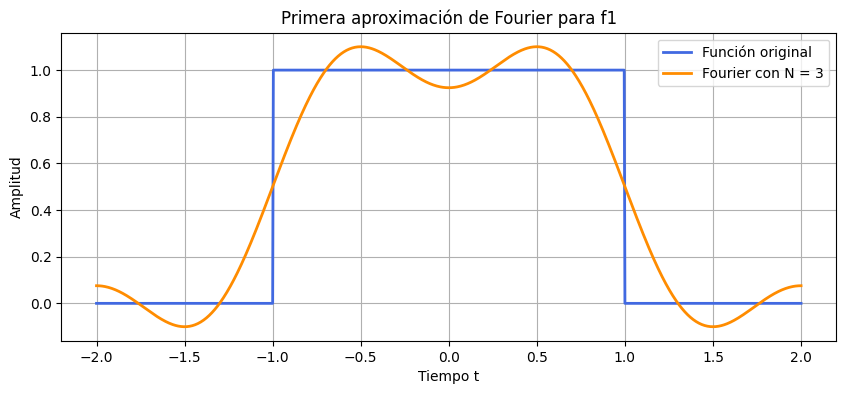

In [92]:
tiempos = np.linspace(-2, 2, 1001)

original = funcion_1_periodica(tiempos)
aproximacion = serie_fourier(funcion_1, tiempos, N=3)

plt.figure(figsize=(10, 4))

plt.plot(
    tiempos,
    original,
    label="Función original",
    color="royalblue",
    linewidth=2
)

plt.plot(
    tiempos,
    aproximacion,
    label="Fourier con N = 3",
    color="darkorange",
    linewidth=2
)

plt.xlabel("Tiempo t")
plt.ylabel("Amplitud")
plt.title("Primera aproximación de Fourier para f1")
plt.legend()
plt.grid(True)
plt.show()

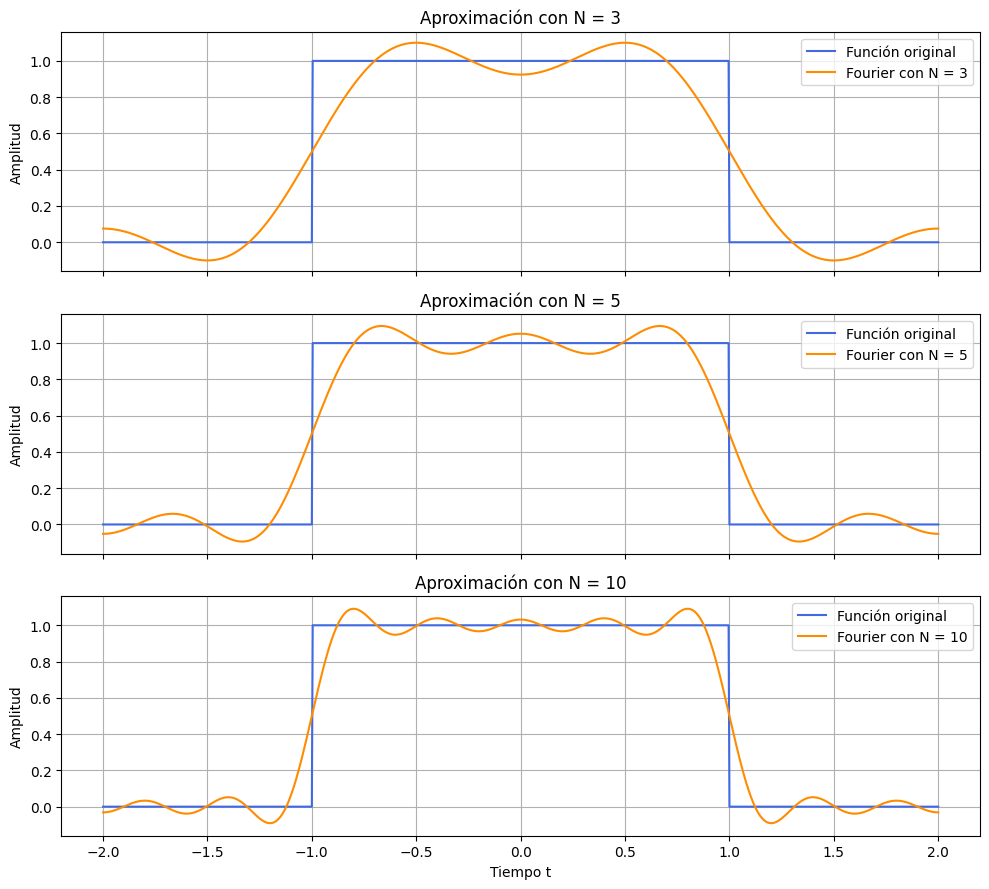

In [93]:
tiempos = np.linspace(-2, 2, 1001)
original = funcion_1_periodica(tiempos)

fig, ejes = plt.subplots(
    3, 1,
    figsize=(10, 9),
    sharex=True,
    sharey=True
)

for ax, N in zip(ejes, [3, 5, 10]):
    aproximacion = serie_fourier(funcion_1, tiempos, N)

    ax.plot(
        tiempos, original,
        color="royalblue",
        label="Función original"
    )

    ax.plot(
        tiempos, aproximacion,
        color="darkorange",
        label=f"Fourier con N = {N}"
    )

    ax.set_title(f"Aproximación con N = {N}")
    ax.set_ylabel("Amplitud")
    ax.grid(True)
    ax.legend()

ejes[-1].set_xlabel("Tiempo t")

fig.tight_layout()
plt.show()

In [94]:
ice_f1 = calcular_ice(funcion_1, 3)
energia_f1 = calcular_energia(funcion_1)

porcentaje_error = 100 * ice_f1 / energia_f1

print(f"ICE: {ice_f1:.6f}")
print(f"Porcentaje de energía del error: {porcentaje_error:.4f}%")
print("¿Cumple el criterio del 2%?", porcentaje_error <= 2)

ICE: 0.099367
Porcentaje de energía del error: 4.9684%
¿Cumple el criterio del 2%? False


In [95]:
N_f1 = encontrar_n(funcion_1)
N_f2 = encontrar_n(funcion_2)

print("N mínimo para f1:", N_f1)
print("N mínimo para f2:", N_f2)

N mínimo para f1: 11
N mínimo para f2: 11


In [96]:
for nombre, funcion in [
    ("f1", funcion_1),
    ("f2", funcion_2)
]:
    energia = calcular_energia(funcion)

    print(f"\nFunción {nombre}")

    for N in [10, 11]:
        error = calcular_ice(funcion, N)
        porcentaje = 100 * error / energia

        print(
            f"N = {N}: "
            f"ICE = {error:.6f}, "
            f"error relativo = {porcentaje:.4f}%, "
            f"cumple: {porcentaje <= 2}"
        )


Función f1
N = 10: ICE = 0.040395, error relativo = 2.0198%, cumple: False
N = 11: ICE = 0.033696, error relativo = 1.6848%, cumple: True

Función f2
N = 10: ICE = 0.198378, error relativo = 2.2890%, cumple: False
N = 11: ICE = 0.171560, error relativo = 1.9795%, cumple: True


# Resultados documentados de la Parte A

Esta sección registra los seis casos solicitados para las funciones originales, responde las preguntas de análisis y estudia la señal propuesta con IA para N = 15. Las salidas se conservan en el notebook y se pueden regenerar ejecutándolo en orden.

## 1. Casos N = 3, 5 y 10 para ambas funciones

Se usa la convención del MAP:
$$S_N(t)=a_0+\sum_{n=1}^N[a_n\cos(n\omega_0t)+b_n\sin(n\omega_0t)],\qquad \omega_0=\frac{2\pi}{T}=\frac{\pi}{2}.$$
Ambas señales tienen período T = 4. Se integran en [-2, 2], separando los puntos de discontinuidad. El valor asignado a un punto aislado no cambia las integrales. El término constante es a₀, sin dividirlo otra vez entre dos.

Para cada caso se presenta: período, N, las 2N+1 posiciones de la expresión, coeficientes, ecuación, energía, ICE y gráfica. La ecuación mostrada usa seis decimales; los cálculos conservan los coeficientes numéricos sin redondear.

In [97]:
from IPython.display import display, Markdown, Math


def documentar_caso(nombre, funcion_base, funcion_periodica, N):
    """Genera una salida fija: mover la interfaz no modifica este registro."""
    a0 = calcular_a0(funcion_base)
    coeficientes = [
        (n, calcular_an(funcion_base, n), calcular_bn(funcion_base, n))
        for n in range(1, N + 1)
    ]
    energia = calcular_energia(funcion_base)
    error = calcular_ice(funcion_base, N)
    porcentaje = 100 * error / energia
    cumple = error <= 0.02 * energia

    display(Markdown(
        f"**{nombre} · N = {N}**\n\n"
        f"Período: **T = {T}**; frecuencia angular: **ω₀ = π/2**; "
        f"posiciones de la expresión: **2N+1 = {2*N+1}**.\n\n"
        f"Energía: **{energia:.8f}**; ICE: **{error:.8f}**; "
        f"ICE/E: **{porcentaje:.4f}%**; cumple 2%: **{'Sí' if cumple else 'No'}**."
    ))
    filas = ['| n | aₙ | bₙ |', '|---:|---:|---:|', f'| 0 | {a0:.6f} | No aplica |']
    terminos = [f'{0.0 if abs(a0)<1e-10 else a0:.6f}']
    for n, an, bn in coeficientes:
        av = 0.0 if abs(an)<1e-10 else an
        bv = 0.0 if abs(bn)<1e-10 else bn
        filas.append(f'| {n} | {av:.6f} | {bv:.6f} |')
        for valor, trig in [(an, 'cos'), (bn, 'sin')]:
            if abs(valor)>=1e-10:
                signo = '+' if valor>0 else '-'
                terminos.append(
                    signo + f'{abs(valor):.6f}' + chr(92) + trig
                    + '(' + str(n) + chr(92) + 'pi t/2)'
                )
    display(Markdown('\n'.join(filas)))
    # Divide las ecuaciones largas en líneas para facilitar la lectura.
    lineas = [''.join(terminos[i:i+3]) for i in range(0,len(terminos),3)]
    ecuacion = (r'\begin{aligned}S_{' + str(N) + r'}(t) &\approx '
                + (r'\\ &\quad ').join(lineas) + r'\end{aligned}')
    display(Math(ecuacion))

    tiempos = np.linspace(-2, 2, 2001)
    with plt.style.context('default'):
        fig, ax = plt.subplots(figsize=(9, 3.7))
        ax.plot(tiempos, funcion_periodica(tiempos), color='#4338ca', lw=2, label='Señal original')
        ax.plot(tiempos, serie_fourier(funcion_base, tiempos, N), color='#ea580c', lw=1.8,
                linestyle='--', label=f'Serie truncada N={N}')
        ax.set(xlabel='Tiempo t', ylabel='Amplitud', title=f'{nombre} · T=4 · N={N} · ICE/E={porcentaje:.4f}%')
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    return {'funcion': nombre, 'N': N, 'energia': energia, 'ICE': error, 'porcentaje': porcentaje}

resultados_casos = []

### f1 con N = 3

**f1 · N = 3**

Período: **T = 4**; frecuencia angular: **ω₀ = π/2**; posiciones de la expresión: **2N+1 = 7**.

Energía: **2.00000000**; ICE: **0.09936726**; ICE/E: **4.9684%**; cumple 2%: **No**.

| n | aₙ | bₙ |
|---:|---:|---:|
| 0 | 0.500000 | No aplica |
| 1 | 0.636620 | 0.000000 |
| 2 | 0.000000 | 0.000000 |
| 3 | -0.212207 | 0.000000 |

<IPython.core.display.Math object>

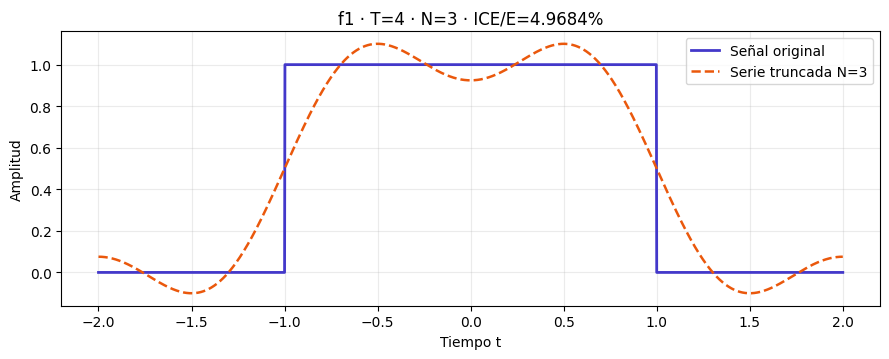

In [98]:
resultados_casos.append(documentar_caso("f1", funcion_1, funcion_1_periodica, 3))

### f1 con N = 5

**f1 · N = 5**

Período: **T = 4**; frecuencia angular: **ω₀ = π/2**; posiciones de la expresión: **2N+1 = 11**.

Energía: **2.00000000**; ICE: **0.06694448**; ICE/E: **3.3472%**; cumple 2%: **No**.

| n | aₙ | bₙ |
|---:|---:|---:|
| 0 | 0.500000 | No aplica |
| 1 | 0.636620 | 0.000000 |
| 2 | 0.000000 | 0.000000 |
| 3 | -0.212207 | 0.000000 |
| 4 | 0.000000 | 0.000000 |
| 5 | 0.127324 | 0.000000 |

<IPython.core.display.Math object>

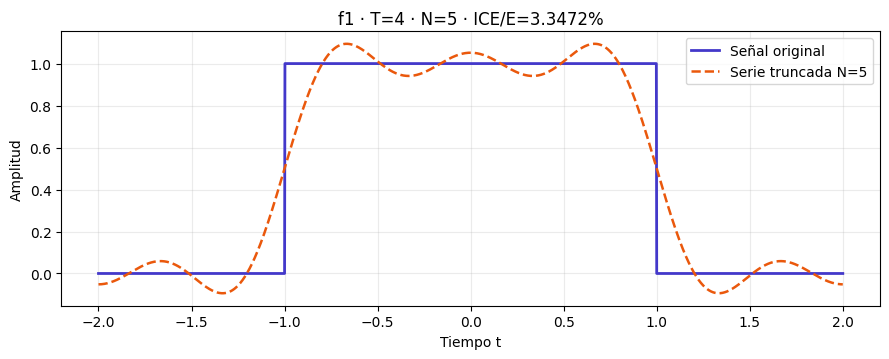

In [99]:
resultados_casos.append(documentar_caso("f1", funcion_1, funcion_1_periodica, 5))

### f1 con N = 10

**f1 · N = 10**

Período: **T = 4**; frecuencia angular: **ω₀ = π/2**; posiciones de la expresión: **2N+1 = 21**.

Energía: **2.00000000**; ICE: **0.04039521**; ICE/E: **2.0198%**; cumple 2%: **No**.

| n | aₙ | bₙ |
|---:|---:|---:|
| 0 | 0.500000 | No aplica |
| 1 | 0.636620 | 0.000000 |
| 2 | 0.000000 | 0.000000 |
| 3 | -0.212207 | 0.000000 |
| 4 | 0.000000 | 0.000000 |
| 5 | 0.127324 | 0.000000 |
| 6 | 0.000000 | 0.000000 |
| 7 | -0.090946 | 0.000000 |
| 8 | 0.000000 | 0.000000 |
| 9 | 0.070736 | 0.000000 |
| 10 | 0.000000 | 0.000000 |

<IPython.core.display.Math object>

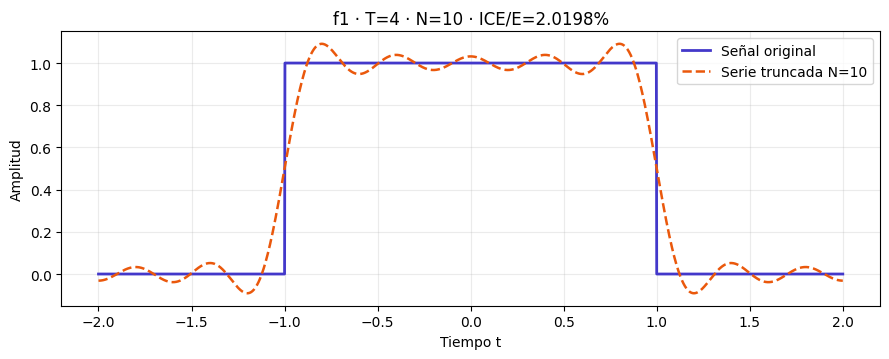

In [100]:
resultados_casos.append(documentar_caso("f1", funcion_1, funcion_1_periodica, 10))

### f2 con N = 3

**f2 · N = 3**

Período: **T = 4**; frecuencia angular: **ω₀ = π/2**; posiciones de la expresión: **2N+1 = 7**.

Energía: **8.66666667**; ICE: **0.52892620**; ICE/E: **6.1030%**; cumple 2%: **No**.

| n | aₙ | bₙ |
|---:|---:|---:|
| 0 | 1.000000 | No aplica |
| 1 | 1.273240 | 0.405285 |
| 2 | 0.000000 | 0.318310 |
| 3 | -0.424413 | -0.045032 |

<IPython.core.display.Math object>

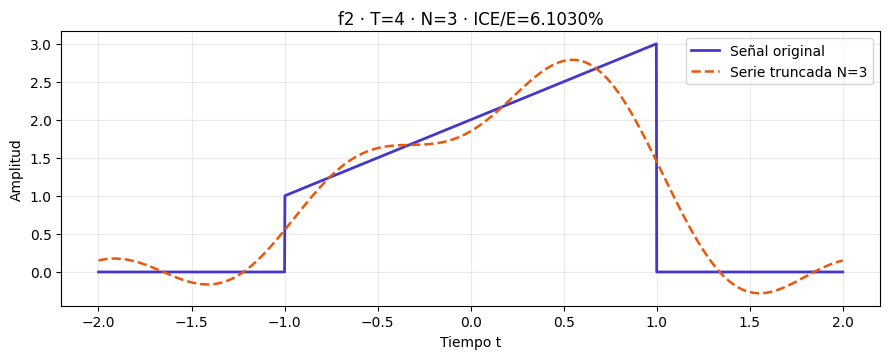

In [101]:
resultados_casos.append(documentar_caso("f2", funcion_2, funcion_2_periodica, 3))

### f2 con N = 5

**f2 · N = 5**

Período: **T = 4**; frecuencia angular: **ω₀ = π/2**; posiciones de la expresión: **2N+1 = 11**.

Energía: **8.66666667**; ICE: **0.34804887**; ICE/E: **4.0159%**; cumple 2%: **No**.

| n | aₙ | bₙ |
|---:|---:|---:|
| 0 | 1.000000 | No aplica |
| 1 | 1.273240 | 0.405285 |
| 2 | 0.000000 | 0.318310 |
| 3 | -0.424413 | -0.045032 |
| 4 | 0.000000 | -0.159155 |
| 5 | 0.254648 | 0.016211 |

<IPython.core.display.Math object>

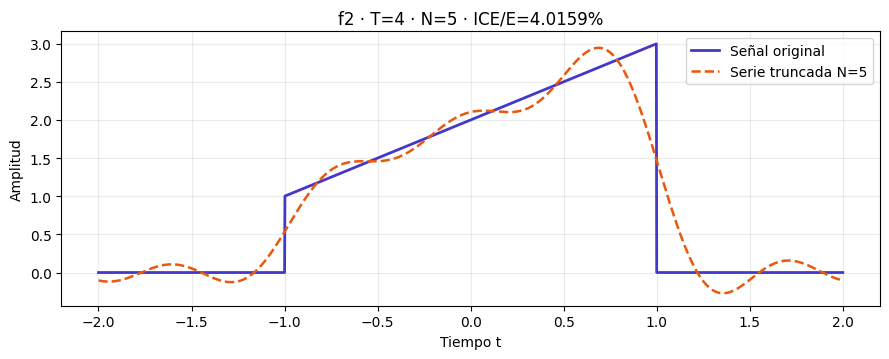

In [102]:
resultados_casos.append(documentar_caso("f2", funcion_2, funcion_2_periodica, 5))

### f2 con N = 10

**f2 · N = 10**

Período: **T = 4**; frecuencia angular: **ω₀ = π/2**; posiciones de la expresión: **2N+1 = 21**.

Energía: **8.66666667**; ICE: **0.19837826**; ICE/E: **2.2890%**; cumple 2%: **No**.

| n | aₙ | bₙ |
|---:|---:|---:|
| 0 | 1.000000 | No aplica |
| 1 | 1.273240 | 0.405285 |
| 2 | 0.000000 | 0.318310 |
| 3 | -0.424413 | -0.045032 |
| 4 | 0.000000 | -0.159155 |
| 5 | 0.254648 | 0.016211 |
| 6 | 0.000000 | 0.106103 |
| 7 | -0.181891 | -0.008271 |
| 8 | 0.000000 | -0.079577 |
| 9 | 0.141471 | 0.005004 |
| 10 | 0.000000 | 0.063662 |

<IPython.core.display.Math object>

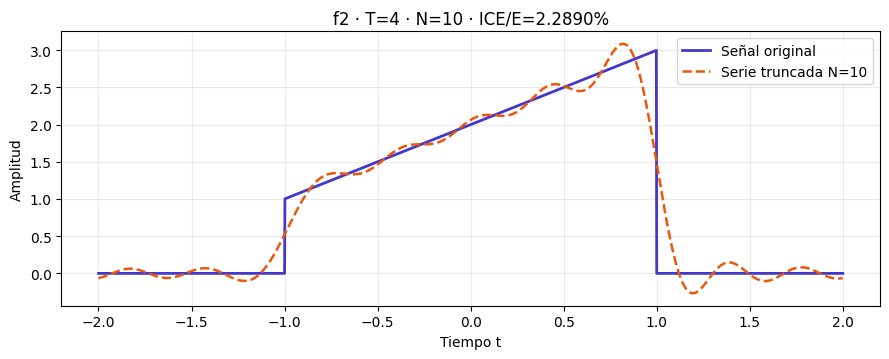

In [103]:
resultados_casos.append(documentar_caso("f2", funcion_2, funcion_2_periodica, 10))

### Resumen de los seis casos
La comparación se realiza con ICE/E porque las señales tienen energías diferentes. Un error absoluto mayor no permite, por sí solo, afirmar que la aproximación relativa sea peor.

In [104]:
filas_resumen = [
    '| Función | N | Energía | ICE | ICE/E (%) | Cumple 2% |',
    '|---|---:|---:|---:|---:|---|'
]
for r in resultados_casos:
    filas_resumen.append(
        f"| {r['funcion']} | {r['N']} | {r['energia']:.6f} | {r['ICE']:.6f} | "
        f"{r['porcentaje']:.4f} | {'Sí' if r['porcentaje']<=2 else 'No'} |"
    )
display(Markdown('\n'.join(filas_resumen)))

| Función | N | Energía | ICE | ICE/E (%) | Cumple 2% |
|---|---:|---:|---:|---:|---|
| f1 | 3 | 2.000000 | 0.099367 | 4.9684 | No |
| f1 | 5 | 2.000000 | 0.066944 | 3.3472 | No |
| f1 | 10 | 2.000000 | 0.040395 | 2.0198 | No |
| f2 | 3 | 8.666667 | 0.528926 | 6.1030 | No |
| f2 | 5 | 8.666667 | 0.348049 | 4.0159 | No |
| f2 | 10 | 8.666667 | 0.198378 | 2.2890 | No |

## 2. Respuestas justificadas

### a) ¿En cuál de las dos funciones converge más rápido la serie?

En los casos estudiados, **f1 presenta menor error relativo**: para N = 3, 5 y 10 obtiene aproximadamente 4.9684%, 3.3472% y 2.0198%, frente a 6.1030%, 4.0159% y 2.2890% de f2. Por lo tanto, con el mismo número máximo de armónicos, f1 ofrece una mejor aproximación bajo el criterio energético relativo.

Esta diferencia es coherente con los saltos de las señales: f1 tiene saltos de magnitud 1 en ambos extremos del pulso, mientras que f2 tiene saltos de magnitudes 1 y 3. No obstante, **ambas alcanzan el umbral del 2% por primera vez en N = 11**. No debe concluirse que f1 necesita menos armónicos para este umbral particular.

Ambas tienen discontinuidades y coeficientes que decaen, en general, como 1/n; la cola de energía del error tiene orden 1/N. La comparación anterior describe el error de los casos concretos, no un orden asintótico de convergencia distinto.

### b) ¿Es útil calcular la ICE para ambas funciones?

Sí. Permite cuantificar el error cuadrático sobre un período y elegir N mediante un criterio reproducible:
$$\mathrm{ICE}(N)=\int_{-2}^{2}[f(t)-S_N(t)]^2dt
=E_f-Ta_0^2-\frac{T}{2}\sum_{n=1}^N(a_n^2+b_n^2).$$
La igualdad se debe a la ortogonalidad y a que usamos los coeficientes de Fourier de la función. Las energías son E₁ = 2 y E₂ = 26/3. Comparar ICE/E permite expresar el error respecto al tamaño de cada señal.

La ICE no mide el error máximo en cada punto. Cerca de los saltos persisten oscilaciones de Gibbs: al aumentar N, la zona afectada se estrecha, pero el sobreimpulso relativo no desaparece. En el salto, la serie converge al promedio de los límites laterales. Por ello, cumplir el 2% energético no significa estar a menos del 2% de la función en todos los tiempos.

### c) ¿Con cuántas iteraciones se obtiene una mejor aproximación?

Interpretamos “iteraciones” como el armónico máximo N utilizado en la suma. Entre los tres casos pedidos, N = 10 tiene la menor ICE para cada función, pero todavía no satisface el 2%. El mínimo que cumple el criterio es **N = 11 para ambas**:

| Función | ICE/E con N = 10 | ICE/E con N = 11 |
|---|---:|---:|
| f1 | 2.0198% | 1.6848% |
| f2 | 2.2890% | 1.9795% |

La búsqueda prueba todos los valores anteriores y se detiene en el primer cumplimiento. Además, agregar un armónico reduce la ICE en T(aₙ²+bₙ²)/2, una cantidad no negativa; por tanto, la ICE nunca aumenta. Puede mantenerse igual cuando los nuevos coeficientes son cero, como ocurre con los armónicos pares de f1. No existe un N finito que reproduzca exactamente todas las discontinuidades.

## 3. Señal periódica propuesta con IA

Se propone una señal sintética que combina tres componentes sinusoidales y una conmutación brusca. Es un ejemplo matemático, no una grabación ni un modelo validado de un instrumento real.

En el intervalo base [-2, 2):
$$g(t)=\sin(\pi t/2)+0.45\sin(3\pi t/2)+0.20\cos(5\pi t/2)+0.35q(t),$$
$$q(t)=\begin{cases}-1,&-2\le t<0,\\+1,&0\le t<2.\end{cases}$$
La señal se extiende periódicamente con **T = 4**. Las tres sinusoides corresponden a los armónicos 1, 3 y 5. El término q introduce saltos en t = 0 y en los límites del período, por lo que la señal requiere infinitos armónicos para una representación exacta.

La implementación está en `funcion_ia` y `funcion_ia_periodica`, dentro de la celda de la interfaz. La integración numérica separa también el punto t = 0. La señal fue propuesta con asistencia de IA durante esta conversación; la evidencia mediante capturas se incorporará posteriormente.

### Coeficientes esperados y comprobación

Por linealidad y por la serie de la onda cuadrada:
$$a_0=0,\qquad a_n=\begin{cases}0.20,&n=5,\\0,&n\ne5,\end{cases}$$
$$b_n=\mathbf{1}_{n=1}+0.45\mathbf{1}_{n=3}+\begin{cases}\dfrac{1.4}{n\pi},&n\text{ impar},\\0,&n\text{ par}.\end{cases}$$
Aquí la función indicadora vale 1 cuando se cumple la condición y 0 en otro caso. Estas expresiones permiten comprobar de manera independiente los coeficientes calculados por integración.

Coeficientes de IA verificados para los armónicos 1 a 15.


**Señal IA · N = 15**

Período: **T = 4**; frecuencia angular: **ω₀ = π/2**; posiciones de la expresión: **2N+1 = 31**.

Energía: **5.02491567**; ICE: **0.01239577**; ICE/E: **0.2467%**; cumple 2%: **Sí**.

| n | aₙ | bₙ |
|---:|---:|---:|
| 0 | 0.000000 | No aplica |
| 1 | 0.000000 | 1.445634 |
| 2 | 0.000000 | 0.000000 |
| 3 | 0.000000 | 0.598545 |
| 4 | 0.000000 | 0.000000 |
| 5 | 0.200000 | 0.089127 |
| 6 | 0.000000 | 0.000000 |
| 7 | 0.000000 | 0.063662 |
| 8 | 0.000000 | 0.000000 |
| 9 | 0.000000 | 0.049515 |
| 10 | 0.000000 | 0.000000 |
| 11 | 0.000000 | 0.040512 |
| 12 | 0.000000 | 0.000000 |
| 13 | 0.000000 | 0.034280 |
| 14 | 0.000000 | 0.000000 |
| 15 | 0.000000 | 0.029709 |

<IPython.core.display.Math object>

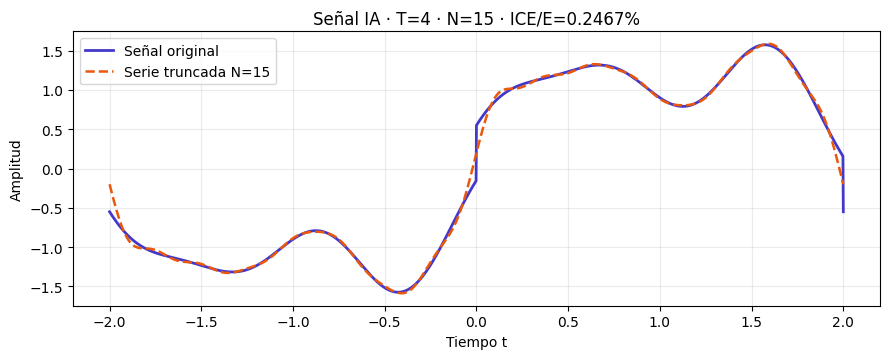

In [105]:
for n in range(1, 16):
    an_esperado = 0.20 if n == 5 else 0.0
    bn_esperado = (
        (1.0 if n == 1 else 0.0)
        + (0.45 if n == 3 else 0.0)
        + (1.4 / (n * np.pi) if n % 2 else 0.0)
    )
    assert np.isclose(calcular_an(funcion_ia, n), an_esperado, atol=1e-9)
    assert np.isclose(calcular_bn(funcion_ia, n), bn_esperado, atol=1e-9)
print('Coeficientes de IA verificados para los armónicos 1 a 15.')

resultado_ia = documentar_caso('Señal IA', funcion_ia, funcion_ia_periodica, 15)

### ¿Es adecuada la aproximación con N = 15?

Sí, **según el criterio de energía del MAP**. La energía total es aproximadamente 5.02491567, y la ICE para N = 15 es aproximadamente 0.01239577. Su cociente es cerca del **0.2467%**, inferior al límite del 2%. La celda anterior calcula estos valores sin redondear antes de hacer la comparación.

La suma incluye exactamente las tres sinusoides originales y los armónicos impares de la onda cuadrada hasta 15. Esto explica la buena coincidencia lejos de los saltos. Cerca de t = 0 y de los límites del período quedan oscilaciones y una transición suave: una suma finita de senos y cosenos es continua y no puede reproducir un salto exacto.

La energía total no se obtiene sumando sin más las energías de los cuatro componentes: la onda cuadrada comparte armónicos con los senos de frecuencias 1 y 3 y aparecen términos cruzados. Su valor analítico es
$$E_g=2(1+0.45^2+0.20^2)+4(0.35)^2+\frac{16(0.35)}{\pi}\left(1+\frac{0.45}{3}\right).$$

La conclusión es energética y global; no afirma precisión uniforme en cada instante. Las capturas de los prompts y respuestas quedan pendientes de incorporación según la organización acordada con el equipo.

# MAP Matematica 6: Parte 2, FFT y filtros de imagen (nucleo)
**Responsable:** Tony (B). **Incisos:** 1 (pasa bajas), 2 (pasa altas) y 3 (Blur Detection).

El codigo de la FFT esta en `src/fft_nucleo.py` (unica fuente). Este notebook solo lo usa, lo prueba y genera las figuras para el reporte en `reporte/figuras/`.

**Convencion de frecuencia de corte (declararla en el reporte):** radio normalizado `r` en [0, 1] medido desde el centro del espectro centrado. `r = 0` es la frecuencia cero y `r = 1` es la esquina (frecuencia mas alta). Pasa bajas: se conserva `r <= fc`. Pasa altas: se conserva `r > fc`.

In [106]:
# ======================================================================
# NUCLEO DE LA PARTE 2: FFT (Cooley-Tukey), FFT 2D, filtros y Blur Detection
# Responsable: Tony (B). Este archivo es la unica fuente del codigo de la FFT.
# Regla del proyecto: la FFT implementada NO usa np.fft.fft ni np.fft.fft2.
# (np.fft solo se usa en las pruebas, para comparar, y np.fft.fftshift
#  solo para reordenar el espectro, sin calcular ninguna transformada.)
# ======================================================================

# libreria numerica
import numpy as np
# libreria para cargar y redimensionar imagenes
from PIL import Image
# libreria para listar archivos de una carpeta
from pathlib import Path


# ---------------------------------------------------------------------
# 1. FFT DE COOLEY-TUKEY (1D)
# ---------------------------------------------------------------------

# funcion que verifica si un numero entero es potencia de 2
def es_potencia_de_2(n):
    # una potencia de 2 tiene un solo bit en 1, por eso n & (n-1) vale 0
    return n >= 1 and (n & (n - 1)) == 0


# funcion que implementa el algoritmo FFT de Cooley-Tukey propuesto
def fft_recursiva(x):

    # conversion de la entrada a valores complejos
    x = np.asarray(x, dtype=complex)

    # N es la longitud del ultimo eje; asi la misma funcion transforma un vector (N,) o muchas filas a la vez (F, N) sin cambiar el algoritmo
    N = x.shape[-1]

    # el algoritmo solo funciona si N es potencia de 2
    if not es_potencia_de_2(N):
        
        # aviso claro del error para el usuario
        raise ValueError(f"La longitud debe ser potencia de 2, se recibio N={N}")
    
    # caso base del algoritmo: if N = 1 then return x
    if N == 1:

        # la DFT de un solo elemento es el mismo elemento
        return x
    
    # DFT recursiva de los indices pares: x0, x2, ..., x(N-2)
    x_par = fft_recursiva(x[..., 0::2])

    # DFT recursiva de los indices impares: x1, x3, ..., x(N-1)
    x_impar = fft_recursiva(x[..., 1::2])

    # indices k = 0, 1, ..., N/2 - 1
    k = np.arange(N // 2)

    # factor T = x_impar[k] * e^(-2*pi*i*k/N), calculado para todos los k a la vez
    T = x_impar * np.exp(-2j * np.pi * k / N)

    # X[k] = x_par[k] + T  y  X[k + N/2] = x_par[k] - T, unidos en un solo arreglo
    return np.concatenate([x_par + T, x_par - T], axis=-1)


# funcion que calcula la inversa usando la propiedad: IFFT(X) = conj(FFT(conj(X))) / N
def ifft_recursiva(X):

    # conversion de la entrada a valores complejos
    X = np.asarray(X, dtype=complex)

    # longitud de la secuencia
    N = X.shape[-1]

    # conjugar, aplicar la FFT, conjugar de nuevo y dividir entre N
    return np.conj(fft_recursiva(np.conj(X))) / N


# funcion de referencia: DFT directa O(N^2) con la formula del enunciado
def dft_directa(x):

    # conversion de la entrada a valores complejos
    x = np.asarray(x, dtype=complex)

    # cantidad de muestras
    N = x.size

    # indices n (columnas) y k (filas)
    n = np.arange(N)
    k = n.reshape((N, 1))

    # X[k] = suma de x[n] * e^(-2*pi*i*k*n/N), escrito como producto matricial
    return np.exp(-2j * np.pi * k * n / N) @ x


# ---------------------------------------------------------------------
# 2. FFT 2D: FFT sobre las filas y luego sobre las columnas
# ---------------------------------------------------------------------

# funcion que calcula la FFT 2D de una imagen (o de un lote de imagenes)
def fft2_recursiva(img):

    # FFT de cada fila (ultimo eje)
    por_filas = fft_recursiva(img)

    # se intercambian filas y columnas, se transforma, y se regresa a la forma original
    return fft_recursiva(por_filas.swapaxes(-1, -2)).swapaxes(-1, -2)


# funcion que calcula la FFT 2D inversa
def ifft2_recursiva(F):

    # IFFT de cada fila
    por_filas = ifft_recursiva(F)

    # IFFT de cada columna (intercambiando ejes igual que en la directa)
    return ifft_recursiva(por_filas.swapaxes(-1, -2)).swapaxes(-1, -2)


# funcion que lleva la frecuencia cero (DC) al centro del espectro (solo reordena)
def centrar_espectro(F):

    # fftshift solo reordena cuadrantes, no calcula ninguna transformada
    return np.fft.fftshift(F, axes=(-2, -1))


# funcion inversa de la anterior
def descentrar_espectro(F):

    # ifftshift deshace el reordenamiento
    return np.fft.ifftshift(F, axes=(-2, -1))


# ---------------------------------------------------------------------
# 3. IMAGENES: carga, ajuste a potencia de 2 e imagen sintetica de respaldo
# ---------------------------------------------------------------------

# funcion que lista las imagenes de una carpeta
def listar_imagenes(carpeta):
    
    # extensiones aceptadas
    extensiones = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

    # carpeta como objeto Path
    carpeta = Path(carpeta)

    # si la carpeta no existe se devuelve una lista vacia
    if not carpeta.exists():
        return []
    
    # archivos con extension valida, ordenados por nombre
    return sorted(p for p in carpeta.iterdir() if p.suffix.lower() in extensiones)


# funcion que carga una imagen, la ajusta a tam x tam y la normaliza a [0, 1]
def cargar_imagen(ruta, tam=256, gris=True):

    # apertura de la imagen
    im = Image.open(ruta)

    # conversion a escala de grises (L) o color (RGB)
    im = im.convert("L" if gris else "RGB")

    # el redimensionado a potencia de 2 es necesario para la FFT recursiva
    im = im.resize((tam, tam), Image.LANCZOS)

    # conversion a decimales entre 0 y 1
    return np.asarray(im, dtype=float) / 255.0


# funcion que genera una imagen de prueba con bordes, texturas y zonas suaves
def imagen_sintetica(tam=256):

    # malla de coordenadas normalizadas entre 0 y 1
    y, x = np.mgrid[0:tam, 0:tam] / tam

    # fondo con gradiente suave
    img = 0.3 + 0.2 * x + 0.1 * y

    # circulo brillante con borde nitido
    img[(x - 0.3) ** 2 + (y - 0.35) ** 2 < 0.04] = 0.9

    # rectangulo oscuro con borde nitido
    img[(0.55 < x) & (x < 0.9) & (0.15 < y) & (y < 0.45)] = 0.1

    # franjas verticales (textura de alta frecuencia)
    franjas = (0.1 < x) & (x < 0.5) & (0.6 < y) & (y < 0.9)
    img[franjas] = 0.5 + 0.4 * np.sign(np.sin(2 * np.pi * 24 * x[franjas]))

    # patron de tablero de ajedrez
    tablero = (0.6 < x) & (x < 0.9) & (0.6 < y) & (y < 0.9)
    img[tablero] = 0.5 + 0.4 * np.sign(np.sin(2 * np.pi * 12 * x[tablero]) * np.sin(2 * np.pi * 12 * y[tablero]))
    
    # se asegura el rango [0, 1]
    return np.clip(img, 0, 1)


# funcion que aplica una funcion de filtrado a cada canal si la imagen es de color
def aplicar_por_canal(funcion, img, *args, **kwargs):
    # imagen en gris: se aplica directo
    if img.ndim == 2:
        return funcion(img, *args, **kwargs)
    # imagen a color: se filtra cada canal por separado y se vuelven a apilar
    return np.stack([funcion(img[..., c], *args, **kwargs) for c in range(img.shape[-1])], axis=-1)


# ---------------------------------------------------------------------
# 4. FILTROS EN FRECUENCIA
# Convencion de frecuencia de corte (declarar en el reporte):
#   radio normalizado r en [0, 1] medido desde el centro del espectro centrado.
#   r = 0 es la frecuencia cero (DC) y r = 1 es la esquina (frecuencia mas alta).
# ---------------------------------------------------------------------

# funcion que calcula el radio normalizado de cada punto del espectro centrado
def radio_normalizado(forma):
    # alto y ancho de la imagen
    H, W = forma
    # coordenadas verticales y horizontales respecto al centro (indice H//2, W//2)
    fy = (np.arange(H) - H // 2) / (H / 2)
    fx = (np.arange(W) - W // 2) / (W / 2)
    # distancia al centro; se divide entre raiz de 2 para que la esquina valga 1
    return np.sqrt(fx[None, :] ** 2 + fy[:, None] ** 2) / np.sqrt(2)


# funcion que construye la mascara del filtro pasa bajas
def mascara_pasabajas(forma, fc, tipo="ideal"):
    # radio normalizado de cada punto
    r = radio_normalizado(forma)
    # filtro ideal: deja pasar todo lo que esta dentro del radio fc
    if tipo == "ideal":
        return (r <= fc).astype(float)
    # filtro gaussiano: atenuacion suave (sin el efecto de anillos del ideal)
    if tipo == "gaussiano":
        return np.exp(-(r ** 2) / (2 * fc ** 2))
    # tipo no reconocido
    raise ValueError("tipo debe ser 'ideal' o 'gaussiano'")


# funcion que construye la mascara del filtro pasa altas (complemento del pasa bajas)
def mascara_pasaaltas(forma, fc, tipo="ideal"):
    # lo que no pasa en el pasa bajas, pasa en el pasa altas
    return 1.0 - mascara_pasabajas(forma, fc, tipo)


# funcion que aplica una mascara a una imagen en gris usando la FFT propia
def filtrar_con_mascara(img, mascara):
    # FFT 2D propia y centrado del espectro
    F = centrar_espectro(fft2_recursiva(img))
    # multiplicacion del espectro por la mascara
    F_filtrada = F * mascara
    # regreso al dominio espacial con la IFFT 2D propia
    resultado = ifft2_recursiva(descentrar_espectro(F_filtrada))
    # la parte imaginaria es solo error numerico; se conserva la real
    return resultado.real


# funcion que aplica un pasa bajas a una imagen (gris o color)
def filtro_pasabajas(img, fc, tipo="ideal"):
    # mascara segun el tamano de los dos primeros ejes
    mascara = mascara_pasabajas(img.shape[:2], fc, tipo)
    # filtrado canal por canal y recorte al rango valido [0, 1]
    return np.clip(aplicar_por_canal(filtrar_con_mascara, img, mascara), 0, 1)


# funcion que aplica un pasa altas a una imagen (gris o color)
def filtro_pasaaltas(img, fc, tipo="ideal"):
    # mascara segun el tamano de los dos primeros ejes
    mascara = mascara_pasaaltas(img.shape[:2], fc, tipo)
    # el resultado puede tener valores negativos (no tiene componente DC), no se recorta
    return aplicar_por_canal(filtrar_con_mascara, img, mascara)


# funcion que escala una imagen a [0, 1] solo para poder mostrarla
def normalizar_para_mostrar(img):
    # minimo y maximo de la imagen
    mn, mx = img.min(), img.max()
    # si es constante se devuelve ceros para evitar dividir entre 0
    return np.zeros_like(img) if mx == mn else (img - mn) / (mx - mn)


# funcion que desenfoca una imagen con un pasa bajas gaussiano (sirve para pruebas)
def desenfoque_gaussiano(img, fc=0.05):
    # un fc pequeno elimina casi todas las frecuencias altas
    return filtro_pasabajas(img, fc, tipo="gaussiano")


# ---------------------------------------------------------------------
# 5. BLUR DETECTION
# Idea: una imagen nitida tiene bordes, y los bordes son frecuencias altas.
# Si falta energia en altas frecuencias, la imagen esta desenfocada.
# ---------------------------------------------------------------------

# funcion que mide que fraccion de la energia espectral esta en altas frecuencias
def puntaje_blur_fft(img, fc_alta=0.1):
    # si la imagen es de color se pasa a gris con promedio de canales
    if img.ndim == 3:
        img = img.mean(axis=-1)
    # espectro centrado y potencia |F|^2
    potencia = np.abs(centrar_espectro(fft2_recursiva(img))) ** 2
    # radio normalizado de cada punto
    r = radio_normalizado(img.shape)
    # se ignora la componente DC (brillo promedio), que no aporta informacion de nitidez
    potencia[img.shape[0] // 2, img.shape[1] // 2] = 0
    # energia total sin DC
    total = potencia.sum()
    # fraccion de la energia que cae fuera del radio fc_alta
    return float(potencia[r > fc_alta].sum() / total) if total > 0 else 0.0


# funcion de comprobacion: varianza del Laplaciano (metodo clasico de nitidez)
def varianza_laplaciano(img):
    # si la imagen es de color se pasa a gris con promedio de canales
    if img.ndim == 3:
        img = img.mean(axis=-1)
    # Laplaciano discreto con 4 vecinos, calculado con desplazamientos de la matriz
    lap = (-4 * img[1:-1, 1:-1] + img[:-2, 1:-1] + img[2:, 1:-1] + img[1:-1, :-2] + img[1:-1, 2:])
    # nitidez = varianza del Laplaciano
    return float(lap.var())


# funcion que decide si una imagen esta desenfocada comparando el puntaje con un umbral
# umbral=0.02 se obtuvo con imagenes de prueba (nitidas: 0.08 a 0.43; muy desenfocadas: < 0.01)
# el puntaje depende del contenido, por eso hay que recalibrarlo con las imagenes del proyecto
def detectar_desenfoque(img, umbral=0.02, fc_alta=0.1):
    # puntaje de energia en altas frecuencias
    puntaje = puntaje_blur_fft(img, fc_alta)
    # por debajo del umbral falta energia de bordes: desenfocada
    return {"puntaje_fft": puntaje, "laplaciano": varianza_laplaciano(img), "desenfocada": puntaje < umbral}


In [107]:
# librerias para graficar
import numpy as np
import matplotlib.pyplot as plt
# carpeta con las imagenes del proyecto y carpeta de salida de figuras del reporte
CARPETA_IMAGENES = Path("../imagenes/Imagenes de prueba")
CARPETA_FIGURAS = Path("../reporte/figuras")
# se crea la carpeta de figuras si no existe
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
# tamano al que se ajustan las imagenes (potencia de 2, requisito de la FFT recursiva)
TAM = 256

## 0. Pruebas del nucleo
La FFT propia debe coincidir con `np.fft` (que se usa **solo aqui**, para comparar).

In [108]:
# generador aleatorio con semilla fija para que las pruebas sean repetibles
rng = np.random.default_rng(0)
# prueba de la FFT 1D y su inversa con varias longitudes (todas potencias de 2)
for N in [1, 2, 8, 64, 1024]:
    # senal compleja aleatoria de longitud N
    x = rng.normal(size=N) + 1j * rng.normal(size=N)
    # la FFT propia debe coincidir con la de NumPy
    assert np.allclose(fft_recursiva(x), np.fft.fft(x)), f"FFT 1D falla con N={N}"
    # la inversa debe devolver la senal original
    assert np.allclose(ifft_recursiva(fft_recursiva(x)), x), f"IFFT falla con N={N}"
# la DFT directa (formula del enunciado) tambien debe coincidir
assert np.allclose(dft_directa(x[:64]), np.fft.fft(x[:64])), "DFT directa falla"
# prueba de la FFT 2D con imagen cuadrada y con imagen rectangular
for forma in [(64, 64), (32, 128), (256, 256)]:
    # imagen aleatoria
    img_t = rng.random(forma)
    # comparacion con NumPy
    assert np.allclose(fft2_recursiva(img_t), np.fft.fft2(img_t)), f"FFT 2D falla con {forma}"
    # FFT seguida de inversa debe devolver la imagen
    assert np.allclose(ifft2_recursiva(fft2_recursiva(img_t)).real, img_t), f"IFFT 2D falla con {forma}"
# un pasa bajas con fc = 1.0 debe dejar la imagen intacta
prueba = imagen_sintetica(TAM)
assert np.allclose(filtro_pasabajas(prueba, 1.0), prueba), "pasa bajas con fc=1 deberia ser identidad"
# una longitud que no es potencia de 2 debe producir un error claro
try:
    fft_recursiva(np.zeros(6))
    raise AssertionError("debio fallar con N=6")
except ValueError:
    pass
# mensaje de exito
print("Todas las pruebas del nucleo pasaron")

Todas las pruebas del nucleo pasaron


## Carga de imagenes
Coloque las imagenes del proyecto en `imagenes/`. Si la carpeta esta vacia se usa una imagen sintetica de respaldo (con bordes y texturas) para poder probar todo.

In [109]:
# lista de imagenes que hay en la carpeta del proyecto
rutas = listar_imagenes(CARPETA_IMAGENES)
# si hay imagenes se cargan en gris y ajustadas a TAM x TAM
if rutas:
    imagenes = {r.stem: cargar_imagen(r, TAM) for r in rutas}
# si no hay imagenes se usa la sintetica
else:
    imagenes = {"sintetica": imagen_sintetica(TAM)}
    print("AVISO: no hay imagenes en ../imagenes/Imagenes de prueba, se usa la imagen sintetica de respaldo")
# resumen de lo cargado
print("Imagenes a procesar:", list(imagenes))

Imagenes a procesar: ['img1', 'img2', 'img3', 'img4']


## Inciso 1. Filtro pasa bajas (fc = 0.22, 0.15, 0.96)

--- img1: pasa bajas ---
    fc | energia conservada (%) | PSNR (dB)
  0.22 |                  98.41 |     23.44
  0.15 |                  97.40 |     21.28
  0.96 |                 100.00 |     71.98


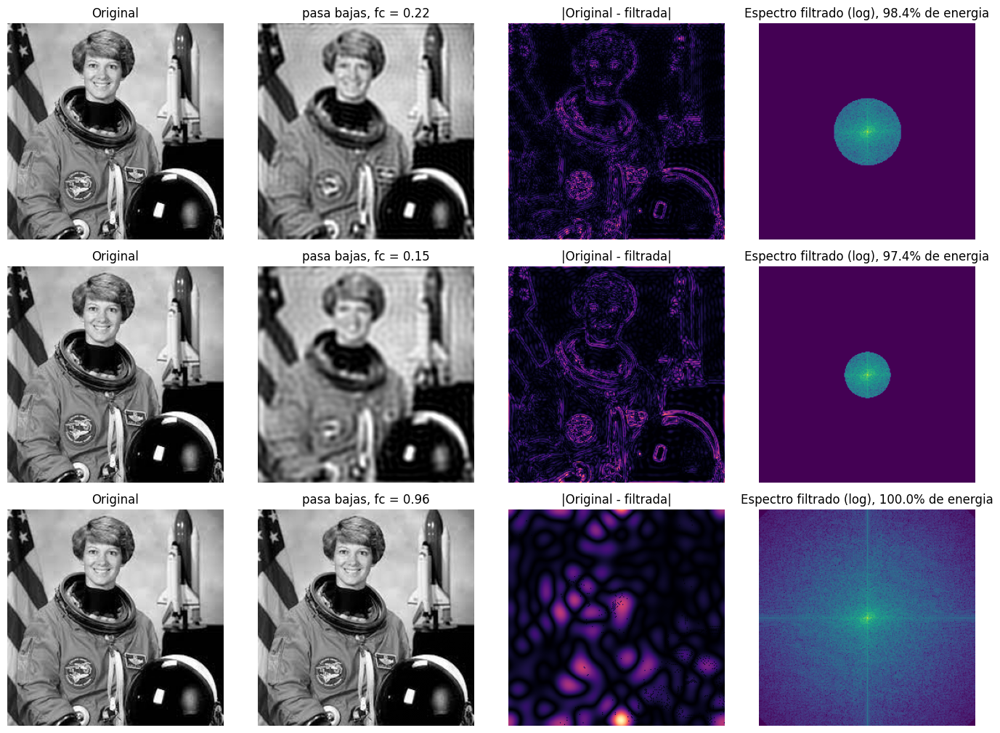

--- img2: pasa bajas ---
    fc | energia conservada (%) | PSNR (dB)
  0.22 |                  99.16 |     25.68
  0.15 |                  98.70 |     23.76
  0.96 |                 100.00 |     64.41


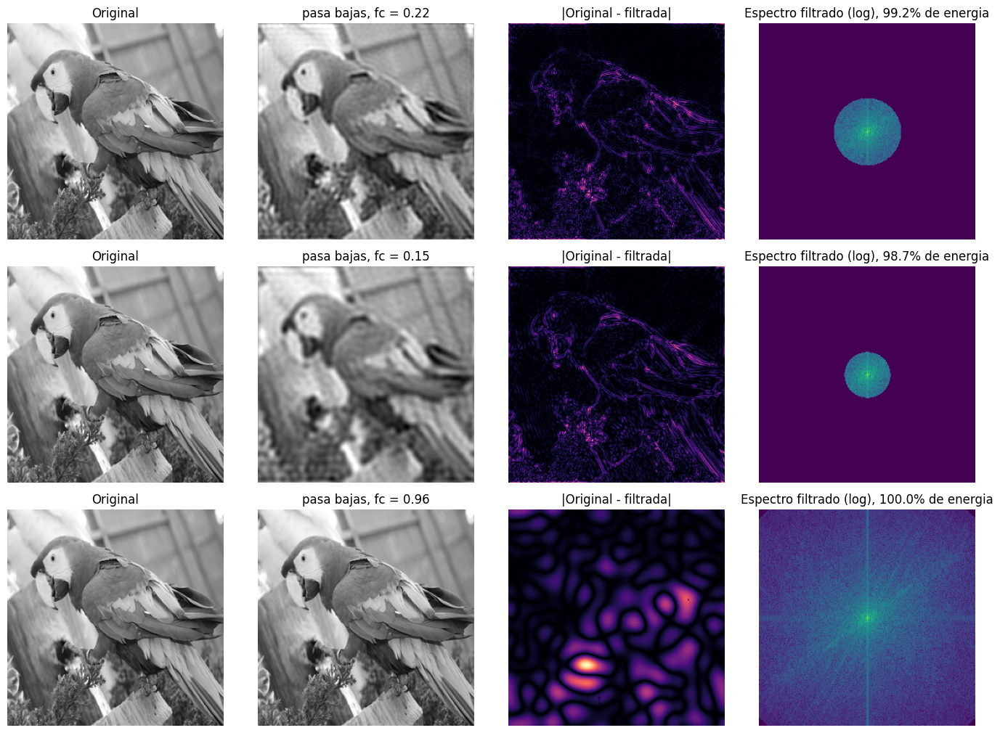

--- img3: pasa bajas ---
    fc | energia conservada (%) | PSNR (dB)
  0.22 |                  99.35 |     26.55
  0.15 |                  98.89 |     24.22
  0.96 |                 100.00 |     69.41


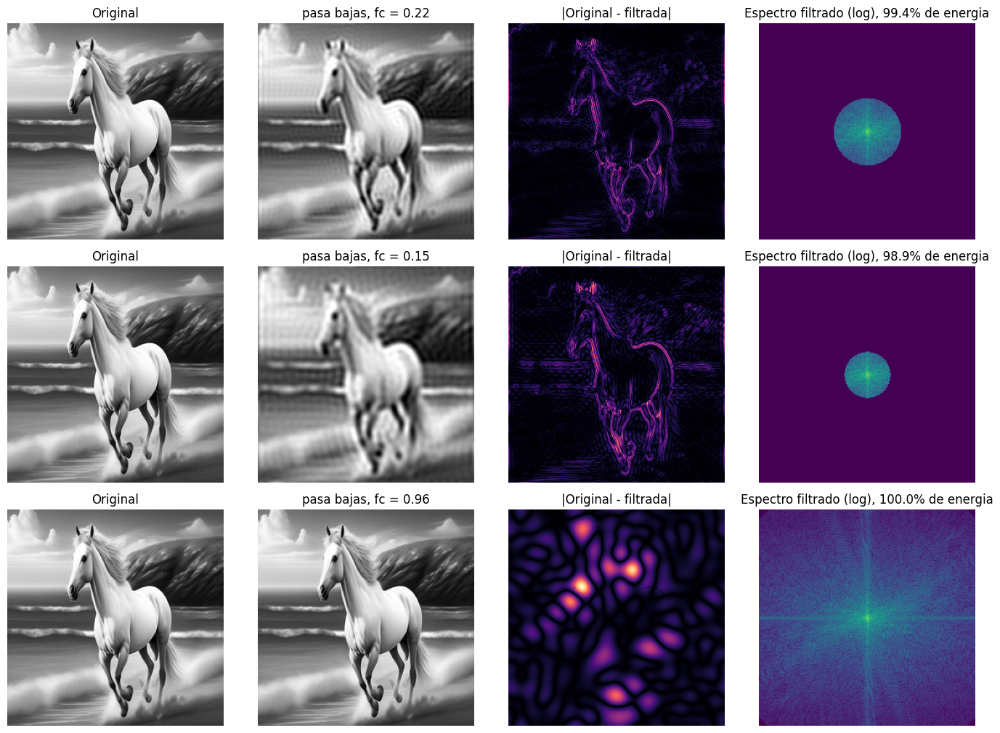

--- img4: pasa bajas ---
    fc | energia conservada (%) | PSNR (dB)
  0.22 |                  98.53 |     25.21
  0.15 |                  97.72 |     23.31
  0.96 |                 100.00 |     68.82


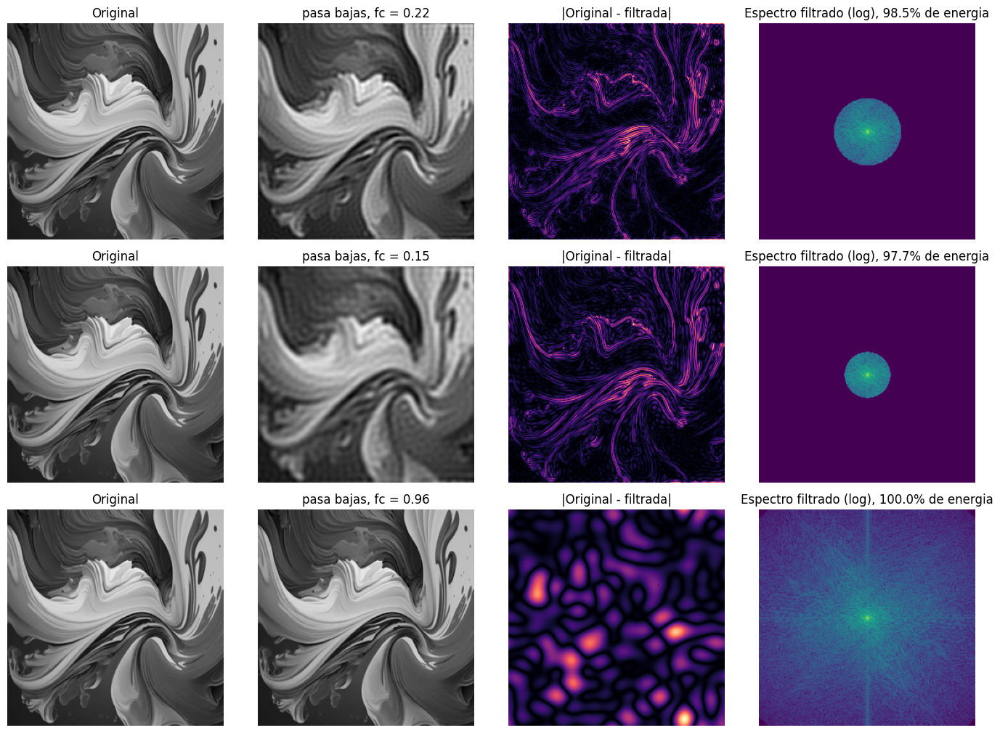

In [110]:
# frecuencias de corte pedidas en el enunciado
FC_BAJAS = [0.22, 0.15, 0.96]


# funcion que calcula la PSNR (en dB) entre la imagen original y la filtrada
def psnr(original, procesada):
    # error cuadratico medio
    mse = np.mean((original - procesada) ** 2)
    # PSNR infinita si no hay error
    return float("inf") if mse == 0 else 10 * np.log10(1.0 / mse)


# funcion que muestra y guarda la comparacion de una imagen con su version filtrada
def mostrar_filtro(nombre, img, fcs, funcion_filtro, funcion_mascara, etiqueta, normalizar=False, con_psnr=True):
    # espectro centrado de la imagen original (se calcula una sola vez)
    F = centrar_espectro(fft2_recursiva(img))
    # energia total del espectro
    energia_total = np.sum(np.abs(F) ** 2)
    # figura con una fila por frecuencia de corte y 4 columnas
    fig, ejes = plt.subplots(len(fcs), 4, figsize=(14, 3.4 * len(fcs)))
    # encabezado de la tabla de resultados numericos
    print(f"--- {nombre}: {etiqueta} ---")
    # la columna PSNR solo se imprime si con_psnr es True (no tiene sentido en el pasa altas)
    print(f"{'fc':>6} | {'energia conservada (%)':>22}" + (f" | {'PSNR (dB)':>9}" if con_psnr else ""))
    # recorrido de cada frecuencia de corte
    for fila, fc in enumerate(fcs):
        # imagen filtrada con la FFT propia
        filtrada = funcion_filtro(img, fc)
        # mascara usada, para visualizar y calcular energia conservada
        mascara = funcion_mascara(img.shape, fc)
        # porcentaje de energia que sobrevive al filtro
        conservada = 100 * np.sum(np.abs(F * mascara) ** 2) / energia_total
        # resultados numericos de esta frecuencia de corte
        print(f"{fc:>6} | {conservada:>22.2f}" + (f" | {psnr(img, np.clip(filtrada, 0, 1)):>9.2f}" if con_psnr else ""))
        # las imagenes pasa altas pueden tener negativos y se escalan solo para mostrarlas
        mostrada = normalizar_para_mostrar(filtrada) if normalizar else filtrada
        # columna 1: original
        ejes[fila, 0].imshow(img, cmap="gray", vmin=0, vmax=1)
        ejes[fila, 0].set_title("Original")
        # columna 2: imagen filtrada
        ejes[fila, 1].imshow(mostrada, cmap="gray", vmin=0, vmax=1)
        ejes[fila, 1].set_title(f"{etiqueta}, fc = {fc}")
        # columna 3: diferencia absoluta con la original
        ejes[fila, 2].imshow(np.abs(img - filtrada), cmap="magma")
        ejes[fila, 2].set_title("|Original - filtrada|")
        # columna 4: espectro (escala log) despues de aplicar la mascara
        ejes[fila, 3].imshow(np.log1p(np.abs(F * mascara)), cmap="viridis")
        ejes[fila, 3].set_title(f"Espectro filtrado (log), {conservada:.1f}% de energia")
    # se quitan los ejes de todas las imagenes
    for ax in ejes.ravel():
        ax.axis("off")
    # ajuste de espacios y guardado para el reporte
    fig.tight_layout()
    fig.savefig(CARPETA_FIGURAS / f"{nombre}_{etiqueta.replace(' ', '_')}.png", dpi=200)
    plt.show()


# aplicacion del pasa bajas a todas las imagenes
for nombre, img in imagenes.items():
    mostrar_filtro(nombre, img, FC_BAJAS, filtro_pasabajas, mascara_pasabajas, "pasa bajas")

#### Inciso 1: pregunta y respuesta

**Pregunta:** ¿Cuál es la diferencia entre las imágenes originales y las generadas? Justifique su respuesta analizando el filtro pasa bajas.

**Respuesta:**

Las imágenes generadas con fc = 0.22 y fc = 0.15 son versiones suavizadas de las originales. Se conservan las formas generales y las zonas de brillo uniforme, pero desaparecen los contornos nítidos y los detalles finos, y junto a los bordes aparecen ondulaciones. Mientras menor es la frecuencia de corte, mayor es la pérdida: con 0.15 el resultado se ve más borroso que con 0.22. En cambio, con fc = 0.96 la imagen generada es prácticamente idéntica a la original (PSNR de 64 a 72 dB según la imagen), ya que casi no se descarta contenido.

El filtro pasa bajas ideal multiplica el espectro centrado por una máscara que vale 1 dentro del radio fc y 0 fuera de él (radio normalizado, donde la esquina del espectro vale 1). Las frecuencias bajas describen variaciones lentas de intensidad, como fondos y superficies, mientras que los bordes y las texturas son transiciones abruptas que necesitan muchas frecuencias altas para representarse. Al eliminarlas, cada borde se reparte en una transición gradual, y eso se percibe como desenfoque. El mapa de diferencia confirma que el error se concentra justo en los contornos.

Las cifras muestran por qué la imagen sigue siendo reconocible. Con fc = 0.22 se conserva solo el 7.6 % de los puntos del espectro y con fc = 0.15 apenas el 3.5 %, pero esos puntos retienen entre 98.4 % y 99.4 % de la energía (0.22) y entre 97.4 % y 98.9 % (0.15), porque en una imagen natural la energía se concentra en las bajas frecuencias. Con fc = 0.96 solo se descarta el 0.3 % del espectro, las esquinas, de modo que la energía conservada es prácticamente 100 %.

Las ondulaciones cercanas a los bordes se deben a que el corte de la máscara es abrupto. Multiplicar por una máscara de borde nítido en frecuencia equivale a convolucionar la imagen con una función tipo sinc en el dominio espacial, cuyos lóbulos laterales generan oscilaciones junto a cada discontinuidad. Es el mismo fenómeno de Gibbs que aparece al truncar una serie de Fourier: aproximar una discontinuidad con un número finito de armónicos produce sobreimpulsos cerca del salto.

## Inciso 2. Filtro pasa altas (fc = 0.23, 0.11, 0.91)
El pasa altas elimina la componente DC, asi que el resultado tiene media cero. Para poder verlo se escala a [0, 1] solo para mostrarlo.

--- img1: pasa altas ---
    fc | energia conservada (%)
  0.23 |                   1.48
  0.11 |                   3.77
  0.91 |                   0.00


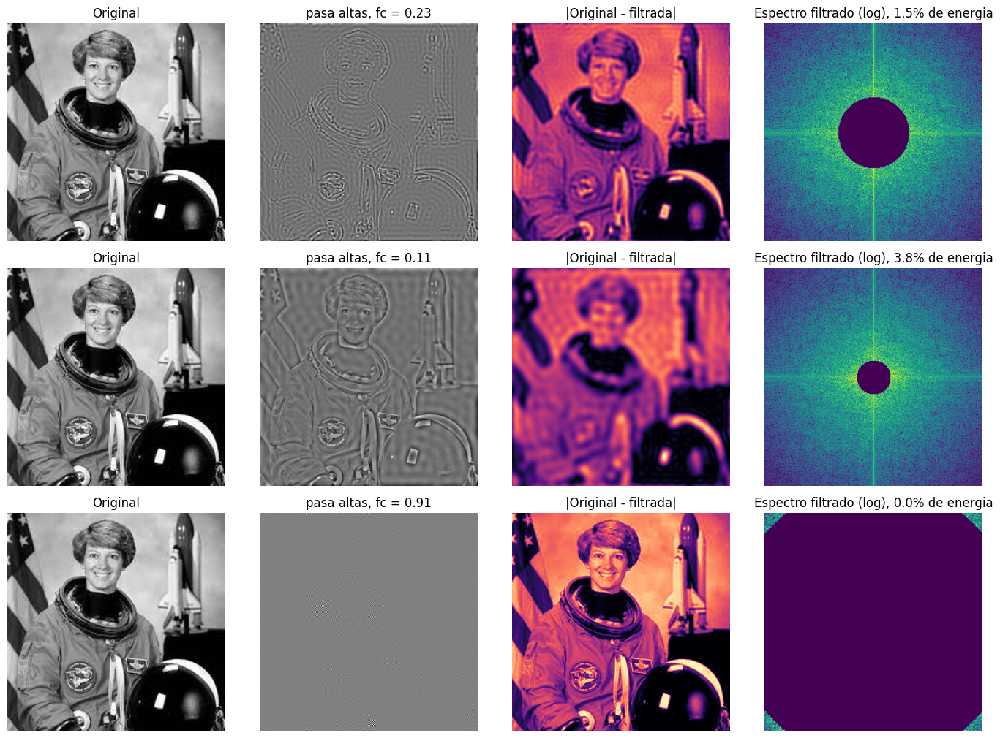

--- img2: pasa altas ---
    fc | energia conservada (%)
  0.23 |                   0.79
  0.11 |                   1.77
  0.91 |                   0.00


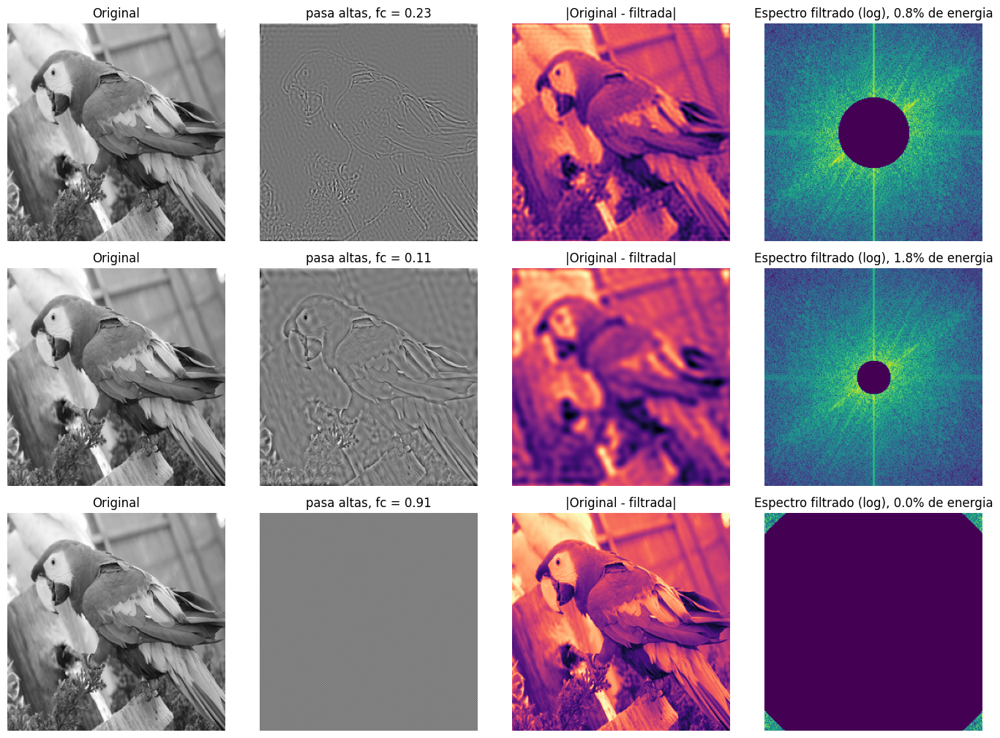

--- img3: pasa altas ---
    fc | energia conservada (%)
  0.23 |                   0.60
  0.11 |                   1.68
  0.91 |                   0.00


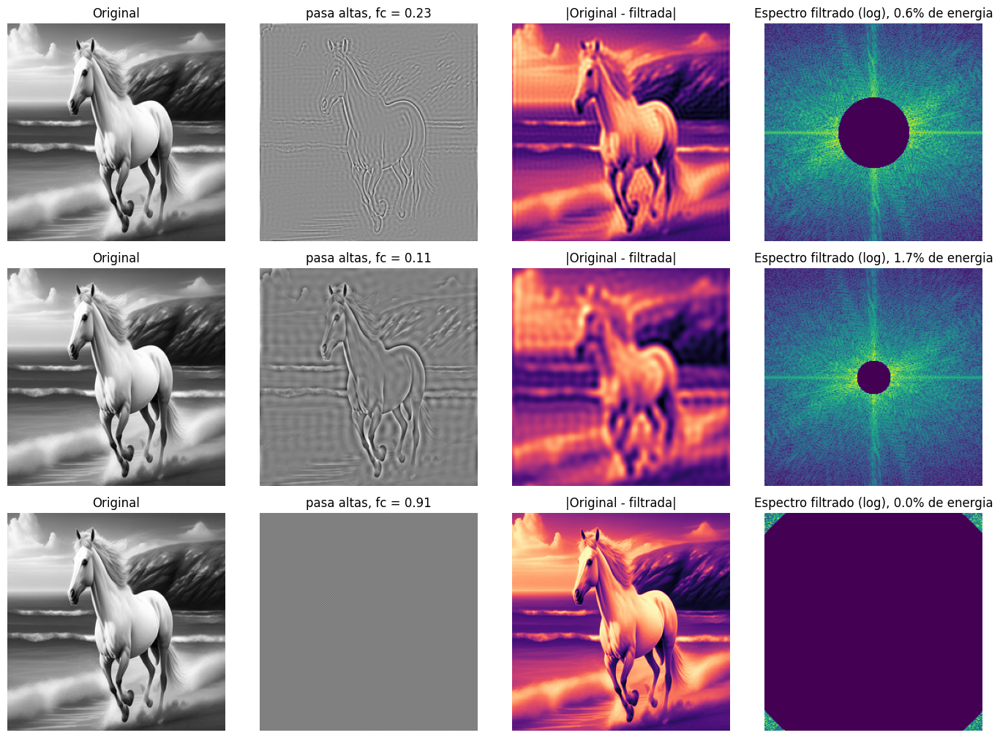

--- img4: pasa altas ---
    fc | energia conservada (%)
  0.23 |                   1.39
  0.11 |                   3.17
  0.91 |                   0.00


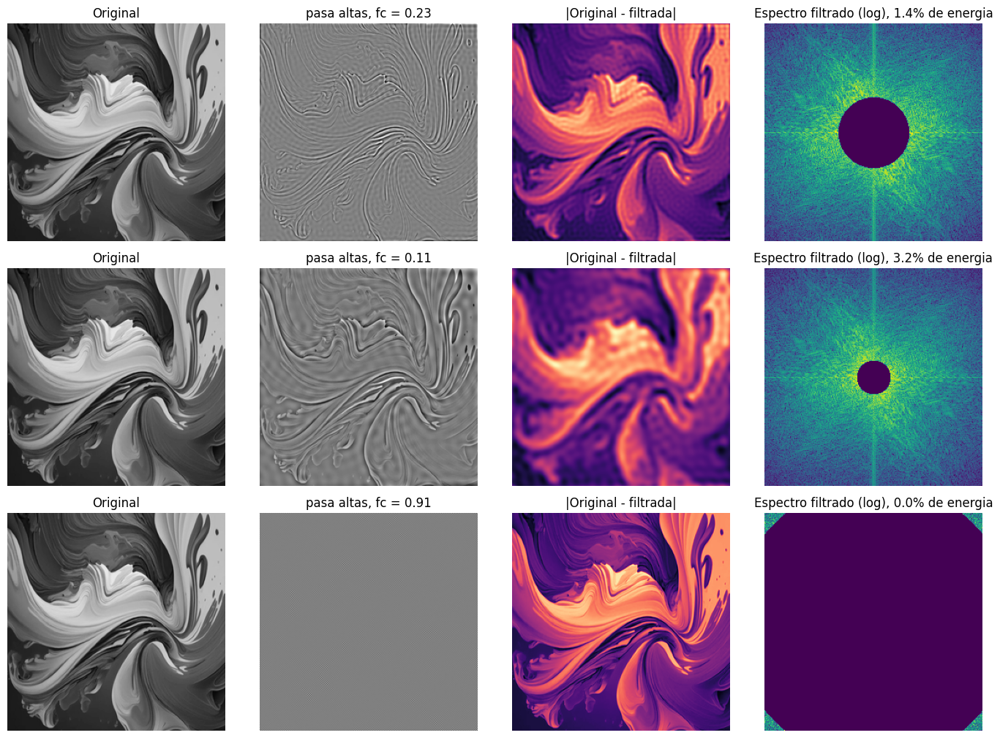

In [111]:
# frecuencias de corte pedidas en el enunciado
FC_ALTAS = [0.23, 0.11, 0.91]
# aplicacion del pasa altas a todas las imagenes (normalizar=True solo afecta la visualizacion; sin PSNR porque el resultado no debe parecerse a la original)
for nombre, img in imagenes.items():
    mostrar_filtro(nombre, img, FC_ALTAS, filtro_pasaaltas, mascara_pasaaltas, "pasa altas", normalizar=True, con_psnr=False)

#### Inciso 2: pregunta y respuesta

**Pregunta:** ¿Cuál es la diferencia entre las imágenes originales y las generadas? Justifique su respuesta analizando el filtro pasa altas.

**Respuesta:**

Las imágenes generadas ya no se parecen a las originales. El resultado es un mapa de bordes y detalles finos sobre un fondo gris uniforme (para poder mostrarlo se escala a [0, 1], de modo que el gris medio corresponde al valor cero). Las zonas suaves, como el cielo o las superficies lisas, desaparecen, y solo quedan los contornos de los objetos. Con fc = 0.11 se conservan más frecuencias intermedias y los bordes se ven más gruesos y con más estructura, mientras que con fc = 0.23 los contornos son más finos. Con fc = 0.91 solo sobreviven las esquinas del espectro y se obtiene un patrón fino casi uniforme, sin contenido reconocible de la escena y con amplitud casi nula (desviación estándar cercana a 0.001 en escala de 0 a 1).

La máscara del pasa altas es el complemento de la del pasa bajas, es decir, vale 0 dentro del radio fc y 1 fuera de él. Como el centro del espectro contiene la frecuencia cero, que representa el brillo promedio, ese valor se elimina y la imagen resultante tiene media cero, con valores positivos y negativos (por eso no se recorta al rango [0, 1]). Como ambas máscaras suman 1, la imagen original es la suma de su versión pasa bajas y su versión pasa altas con el mismo fc.

La energía que sobrevive es pequeña: entre 0.6 % y 1.5 % con fc = 0.23, entre 1.7 % y 3.8 % con fc = 0.11, y prácticamente 0 % con fc = 0.91. Esto ocurre porque la energía de una imagen natural se concentra en las bajas frecuencias, aunque las altas sean justamente las que contienen la información de los bordes. Al bajar fc el filtro deja pasar más frecuencias (hasta el 98.1 % de los puntos del espectro con fc = 0.11), y con ello más energía y más estructura. Al subirlo hasta 0.91 queda solo el 1.7 % de los puntos, las frecuencias más altas, y ya no hay forma de reconstruir los objetos. También se observan ondulaciones alrededor de los contornos, originadas por el corte abrupto de la máscara ideal, igual que en el pasa bajas.

## Inciso 3. Blur Detection
**Metodo:** se calcula la fraccion de la energia espectral (sin la componente DC) que cae en altas frecuencias (`r > 0.1`). Una imagen nitida tiene bordes, es decir, energia en altas frecuencias; una desenfocada la pierde. Se compara con la varianza del Laplaciano como comprobacion independiente.

**Umbral:** el puntaje depende del contenido de la imagen, por eso el umbral por defecto (0.02) debe recalibrarse con las imagenes del proyecto.

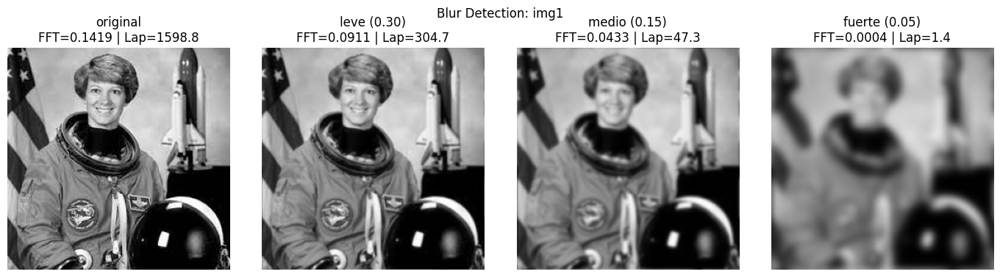

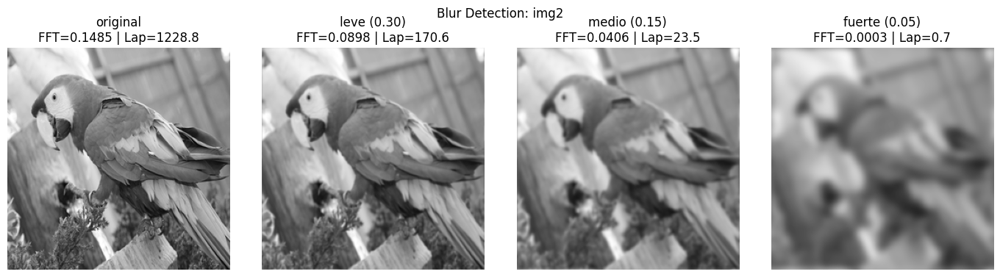

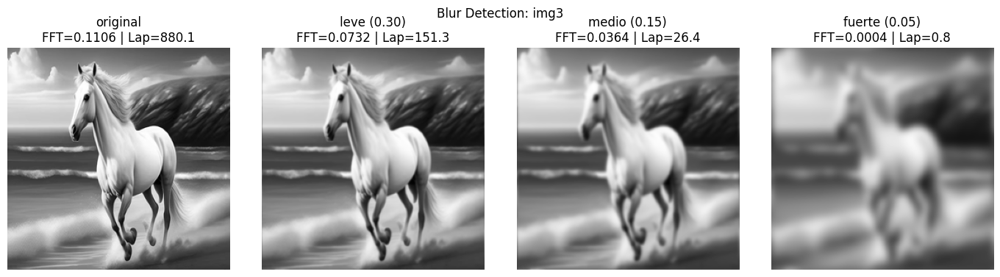

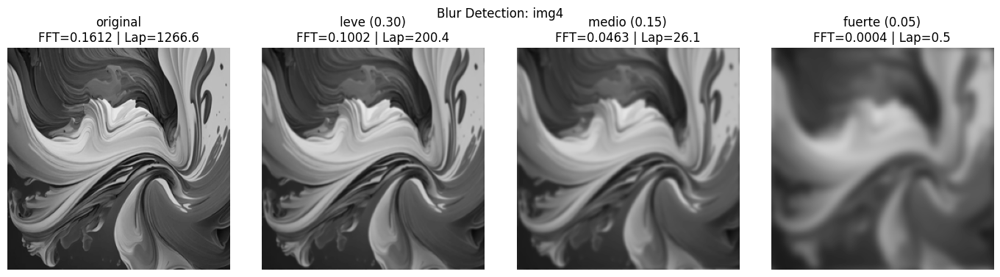

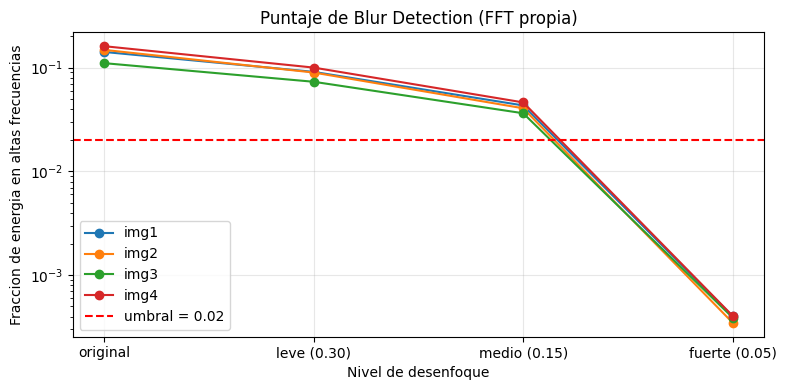

In [112]:
# umbral de decision (ver nota arriba); por debajo de este puntaje se considera desenfocada
UMBRAL = 0.02
# niveles de desenfoque artificial para validar el detector (fc del pasa bajas gaussiano; None = original)
NIVELES = [None, 0.30, 0.15, 0.05]
# nombres de cada nivel para las graficas
ETIQUETAS = ["original", "leve (0.30)", "medio (0.15)", "fuerte (0.05)"]
# diccionario donde se guardan los puntajes para graficarlos despues
puntajes = {}
# recorrido de cada imagen
for nombre, img in imagenes.items():
    # version de la imagen para cada nivel de desenfoque
    versiones = [img if fc is None else desenfoque_gaussiano(img, fc) for fc in NIVELES]
    # puntaje FFT de cada version
    puntajes[nombre] = [puntaje_blur_fft(v) for v in versiones]
    # figura con una columna por nivel
    fig, ejes = plt.subplots(1, len(NIVELES), figsize=(14, 3.8))
    # recorrido de cada version
    for ax, v, etq, p in zip(ejes, versiones, ETIQUETAS, puntajes[nombre]):
        # imagen y su puntaje en el titulo
        ax.imshow(v, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{etq}\nFFT={p:.4f} | Lap={varianza_laplaciano(v) * 255**2:.1f}")
        ax.axis("off")
    # guardado para el reporte
    fig.suptitle(f"Blur Detection: {nombre}")
    fig.tight_layout()
    fig.savefig(CARPETA_FIGURAS / f"{nombre}_blur_niveles.png", dpi=200)
    plt.show()
# grafica de puntaje contra nivel de desenfoque para todas las imagenes
plt.figure(figsize=(8, 4))
# una curva por imagen
for nombre, valores in puntajes.items():
    plt.plot(ETIQUETAS, valores, "o-", label=nombre)
# linea del umbral de decision
plt.axhline(UMBRAL, color="r", linestyle="--", label=f"umbral = {UMBRAL}")
# escala logaritmica porque los puntajes cambian en ordenes de magnitud
plt.yscale("log")
plt.xlabel("Nivel de desenfoque")
plt.ylabel("Fraccion de energia en altas frecuencias")
plt.title("Puntaje de Blur Detection (FFT propia)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "blur_puntajes.png", dpi=200)
plt.show()

In [113]:
# veredicto del detector sobre las imagenes originales del proyecto
print(f"{'imagen':<20} | {'puntaje FFT':>11} | {'var. Laplaciano':>15} | veredicto")
# recorrido de cada imagen
for nombre, img in imagenes.items():
    # resultado del detector con el umbral definido
    r = detectar_desenfoque(img, UMBRAL)
    # impresion de la fila
    print(f"{nombre:<20} | {r['puntaje_fft']:>11.4f} | {r['laplaciano'] * 255**2:>15.1f} | {'DESENFOCADA' if r['desenfocada'] else 'nitida'}")
# prueba: en cada imagen el puntaje debe decrecer al aumentar el desenfoque
for nombre, valores in puntajes.items():
    # cada nivel debe tener menos energia en altas frecuencias que el anterior
    assert all(a > b for a, b in zip(valores, valores[1:])), f"puntaje no decreciente en {nombre}"
# prueba: el desenfoque fuerte debe quedar por debajo del umbral
for nombre, valores in puntajes.items():
    assert valores[-1] < UMBRAL, f"el desenfoque fuerte no se detecta en {nombre}"
# mensaje de exito
print("Pruebas de Blur Detection correctas")

imagen               | puntaje FFT | var. Laplaciano | veredicto
img1                 |      0.1419 |          1598.8 | nitida
img2                 |      0.1485 |          1228.8 | nitida
img3                 |      0.1106 |           880.1 | nitida
img4                 |      0.1612 |          1266.6 | nitida
Pruebas de Blur Detection correctas


# MAP Matematica 6: Parte 2, CNN y comparacion
**Responsable:** Claudia (C). **Incisos:** 4 (CNN, ruido, limpieza) y 5 (comparacion).

Las funciones de FFT y filtros ya existen en `src/fft_nucleo.py` (Tony). Aqui solo se importan.

**Instrucciones:** Investigue sobre filtros de imagen basados en redes neuronales convolucionales (CNN). No es necesario que entrene una red desde cero. Busque un modelo pre-entrenado sencillo para una tarea como eliminación de ruido (denoising) y mejora de la resolución (superresolution). Bibliotecas como `TensorFlow/Keras' o `PyTorch' tienen tutoriales y modelos
disponibles.


In [114]:
#librerias para graficar
import numpy as np
import matplotlib.pyplot as plt
#carpeta con las imagenes del proyecto y carpeta de salida de figuras del reporte
CARPETA_IMAGENES = Path("../imagenes/Imagenes de prueba")
CARPETA_FIGURAS = Path("../reporte/figuras")
#se crea la carpeta de figuras si no existe
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
#PNG individuales de los incisos de CNN y comparacion.
CARPETA_CNN = CARPETA_FIGURAS / "cnn"
for inciso in ("4a", "4b", "4c", "4d", "5"):
    (CARPETA_CNN / inciso).mkdir(parents=True, exist_ok=True)
#tamano al que se ajustan las imagenes (potencia de 2, requisito de la FFT recursiva)
TAM = 256

## Carga de imagenes (misma logica que la parte 2 de Tony)

In [115]:
#lista de imagenes que hay en la carpeta del proyecto
rutas = listar_imagenes(CARPETA_IMAGENES)
#si hay imagenes se cargan en gris y ajustadas a TAM x TAM
if rutas:
    imagenes = {r.stem: cargar_imagen(r, TAM) for r in rutas}
#si no hay imagenes se usa la sintetica
else:
    imagenes = {"sintetica": imagen_sintetica(TAM)}
    print("AVISO: no hay imagenes en ../imagenes/Imagenes de prueba, se usa la imagen sintetica de respaldo")

## Inciso 4a. Modelo CNN preentrenado

Agregue su implementación y utilícela para las imágenes adjuntas en el proyecto.


Modelo: dncnn_gray_blind (KAIR v1.0) | PyTorch: 2.8.0
Dispositivo: cpu | Pesos: /Users/antoniopapadopolo/Library/Mobile Documents/com~apple~CloudDocs/GALILEO/CICLO 6/MATE 6/PROYECTO/final_proj_mate_6/herramientas/model_zoo/dncnn_gray_blind.pth
SHA-256: cc2ac7fa2f248a7f7a3da414a848326634511ec8b5adb7799e857ed788067bfe


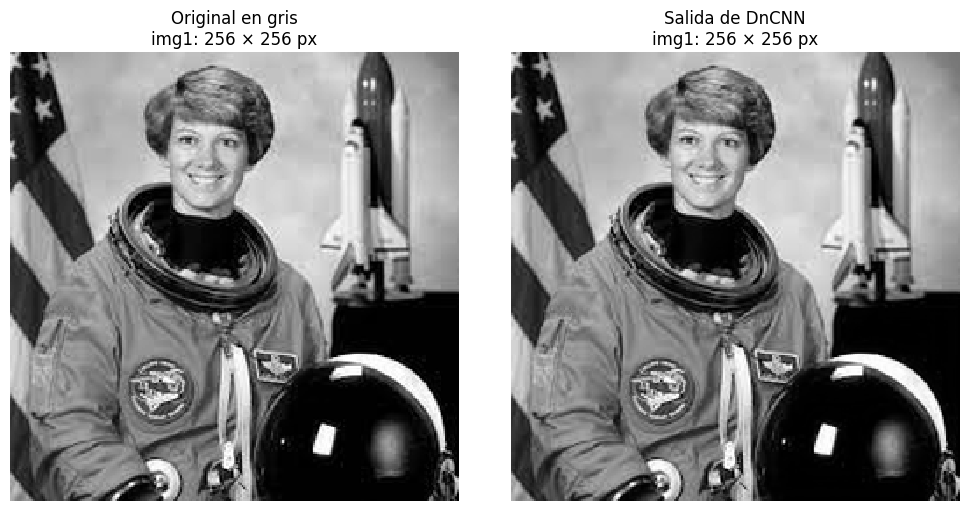

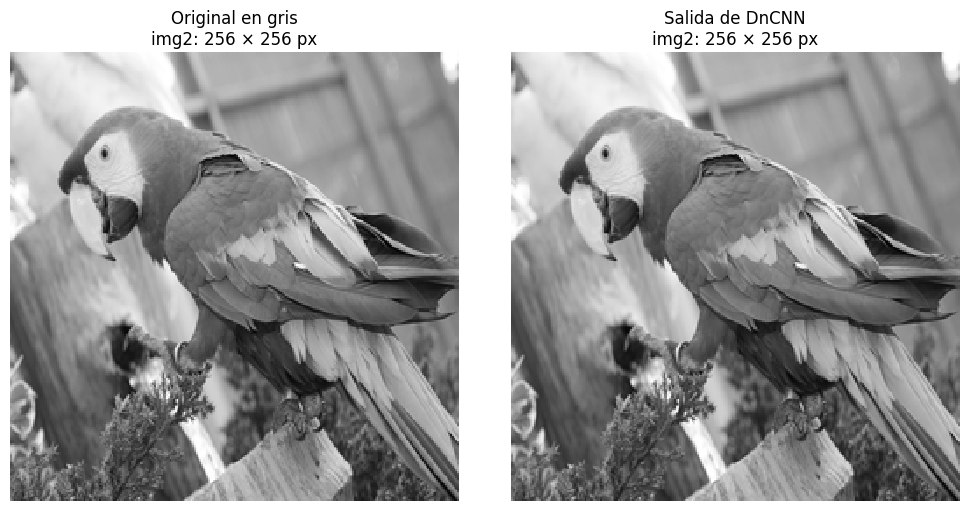

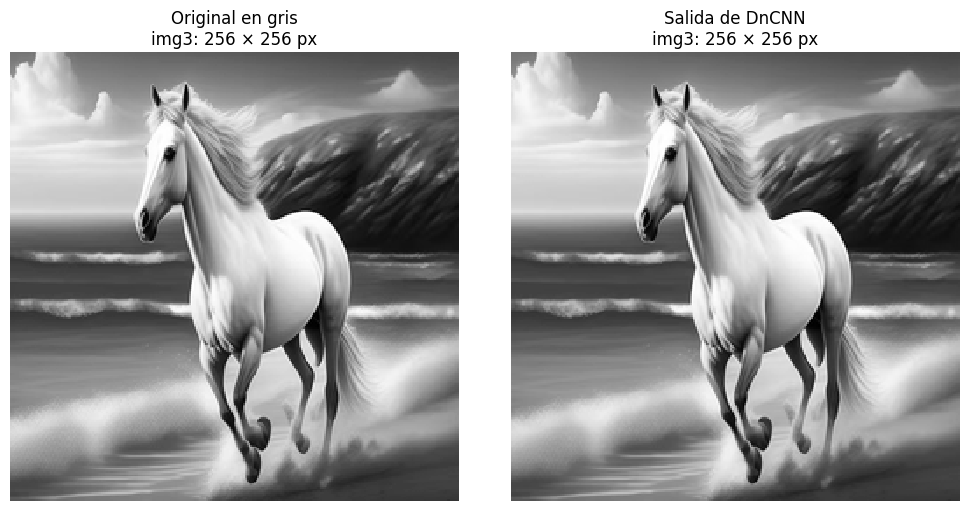

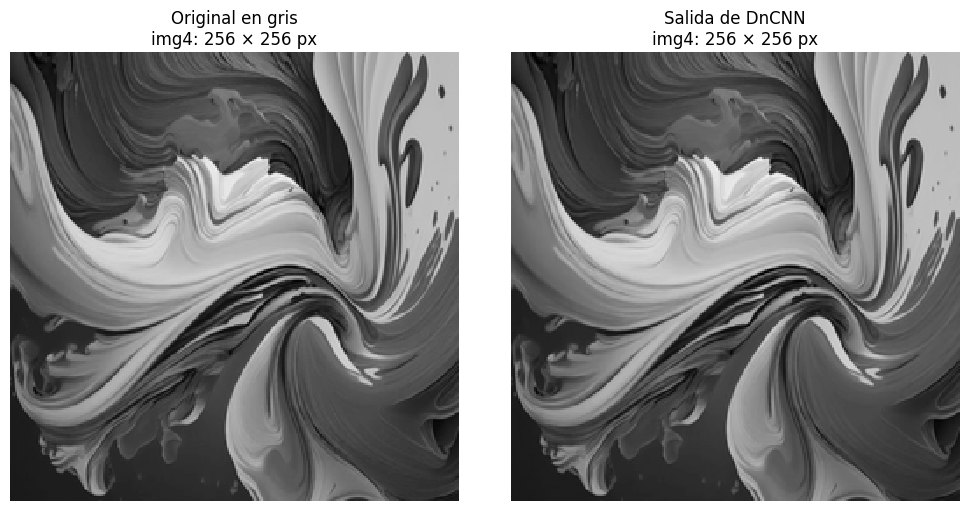

,Imagen,Entrada (ancho × alto),Salida (ancho × alto),Dimensiones conservadas,Valores finitos
0,img1,256 × 256,256 × 256,True,True
1,img2,256 × 256,256 × 256,True,True
2,img3,256 × 256,256 × 256,True,True
3,img4,256 × 256,256 × 256,True,True


4a completado: 4 imágenes procesadas sin entrenamiento.
Inciso 4a: PNG individuales y comparativos guardados en: /Users/antoniopapadopolo/Library/Mobile Documents/com~apple~CloudDocs/GALILEO/CICLO 6/MATE 6/PROYECTO/final_proj_mate_6/reporte/figuras/cnn/4a


In [116]:
#inciso 4a: cargar DnCNN y aplicarla a las imágenes ya preparadas
from pathlib import Path
import hashlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import torch
import torch.nn as nn

#CARPETA_IMAGENES apunta a ../imagenes/Imagenes de prueba; la raiz del proyecto esta dos niveles arriba
RAIZ = CARPETA_IMAGENES.resolve().parent.parent
#ruta local de los pesos preentrenados y direccion de descarga
RUTA_PESOS = RAIZ / "herramientas" / "model_zoo" / "dncnn_gray_blind.pth"
URL_PESOS = "https://github.com/cszn/KAIR/releases/download/v1.0/dncnn_gray_blind.pth"
#si los pesos no existen se descargan una sola vez
if not RUTA_PESOS.is_file():
    #se crea la carpeta donde se guardan los pesos
    RUTA_PESOS.parent.mkdir(parents=True, exist_ok=True)
    print("Descargando los pesos preentrenados de DnCNN...")
    #intento de descarga de los pesos oficiales
    try:
        torch.hub.download_url_to_file(URL_PESOS, str(RUTA_PESOS), progress=True)
    #si la descarga falla se indica como guardar los pesos manualmente
    except Exception as error:
        raise RuntimeError(
            f"No se pudieron descargar los pesos. Descarga {URL_PESOS} "
            f"y guarda el archivo en {RUTA_PESOS}."
        ) from error

#equivalente a KAIR: DnCNN(in_nc=1, out_nc=1, nc=64, nb=20, act_mode='R')
class DnCNNGrayKAIR(nn.Module):
    #funcion que define las capas de la red
    def __init__(self):
        #inicializacion de la clase base de PyTorch
        super().__init__()
        #primera capa convolucional y activacion ReLU
        capas = [nn.Conv2d(1, 64, 3, padding=1), nn.ReLU(inplace=True)]
        #capas intermedias que extraen caracteristicas de la imagen
        for _ in range(18):
            capas.extend([nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(inplace=True)])
        #ultima capa que estima el ruido en un solo canal
        capas.append(nn.Conv2d(64, 1, 3, padding=1))
        #las capas se unen para ejecutarse en orden
        self.model = nn.Sequential(*capas)

    #funcion que resta el ruido estimado de la imagen de entrada
    def forward(self, x):
        return x - self.model(x)

#se usa la GPU si esta disponible o el procesador en caso contrario
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#creacion de la red y carga de los pesos preentrenados
modelo_dncnn_4a = DnCNNGrayKAIR()
estado = torch.load(RUTA_PESOS, map_location="cpu", weights_only=True)
modelo_dncnn_4a.load_state_dict(estado, strict=True)
#se mueve la red al dispositivo y se activa el modo de evaluacion
modelo_dncnn_4a = modelo_dncnn_4a.to(dispositivo).eval()
#se desactiva el calculo de gradientes porque no se entrena la red
modelo_dncnn_4a.requires_grad_(False)

#funcion que aplica la CNN a una imagen en gris
def aplicar_cnn(img):
    """Procesar una imagen gris 2D en [0, 1], conservando su tamaño."""
    #conversion de los pixeles a decimales de 32 bits
    entrada = np.asarray(img, dtype=np.float32)
    #se verifica que la imagen sea una matriz de dos dimensiones no vacia
    if entrada.ndim != 2 or entrada.size == 0:
        raise ValueError("Se requiere una imagen en gris con forma (alto, ancho).")
    #se comprueba que los valores sean finitos y esten entre 0 y 1
    if not np.isfinite(entrada).all() or entrada.min() < 0 or entrada.max() > 1:
        raise ValueError("La imagen debe contener valores finitos en [0, 1].")
    #se agregan los ejes de lote y canal que espera PyTorch
    tensor = torch.from_numpy(entrada.copy())[None, None].to(dispositivo)
    #se procesa la imagen sin calcular gradientes
    with torch.inference_mode():
        prediccion = modelo_dncnn_4a(tensor)
    #se comprueba que la salida conserve el tamano y tenga valores validos
    if prediccion.shape != tensor.shape or not torch.isfinite(prediccion).all().item():
        raise RuntimeError("DnCNN produjo dimensiones o valores inválidos.")
    #se limita la salida a [0, 1] y se devuelve como arreglo de NumPy
    return prediccion.clamp(0, 1)[0, 0].cpu().numpy()

#se muestran el modelo, el dispositivo y la huella de los pesos utilizados
print(f"Modelo: dncnn_gray_blind (KAIR v1.0) | PyTorch: {torch.__version__}")
print(f"Dispositivo: {dispositivo} | Pesos: {RUTA_PESOS}")
print(f"SHA-256: {hashlib.sha256(RUTA_PESOS.read_bytes()).hexdigest()}")

#diccionario de salidas y lista de comprobaciones por imagen
resultados_dncnn_4a = {}
registros = []
#recorrido de las imagenes cargadas para aplicar la CNN
for nombre, entrada in imagenes.items():
    #se procesa la imagen y se conserva el resultado
    salida = aplicar_cnn(entrada)
    resultados_dncnn_4a[nombre] = salida
    #guardado de la entrada y la salida como PNG individuales
    plt.imsave(CARPETA_CNN / "4a" / f"4a_{nombre}_original.png", entrada, cmap="gray", vmin=0, vmax=1)
    plt.imsave(CARPETA_CNN / "4a" / f"4a_{nombre}_dncnn.png", salida, cmap="gray", vmin=0, vmax=1)
    #dimensiones de la imagen para identificar la comparacion
    alto, ancho = entrada.shape
    #figura con la imagen original y la salida de la CNN
    fig, ejes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
    #se muestra cada imagen con la misma escala de grises
    for ax, imagen, titulo in zip(
        ejes, (entrada, salida), ("Original en gris", "Salida de DnCNN")
    ):
        ax.imshow(imagen, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"{titulo}\n{nombre}: {ancho} × {alto} px")
        ax.axis("off")
    #guardado de la figura comparativa en la carpeta del inciso
    fig.savefig(CARPETA_CNN / "4a" / f"4a_{nombre}_dncnn_comparacion.png", dpi=150, bbox_inches="tight")
    #se muestra la figura y se cierra para liberar memoria
    plt.show()
    plt.close(fig)
    #registro de dimensiones y validez de los resultados
    registros.append({
        "Imagen": nombre,
        "Entrada (ancho × alto)": f"{ancho} × {alto}",
        "Salida (ancho × alto)": f"{salida.shape[1]} × {salida.shape[0]}",
        "Dimensiones conservadas": entrada.shape == salida.shape,
        "Valores finitos": bool(np.isfinite(salida).all()),
    })

#tabla con las comprobaciones de todas las imagenes
tabla_4a = pd.DataFrame(registros)
#se muestran la tabla y los mensajes de finalizacion y guardado
display(tabla_4a)
print(f"4a completado: {len(resultados_dncnn_4a)} imágenes procesadas sin entrenamiento.")
print(f"Inciso 4a: PNG individuales y comparativos guardados en: {(CARPETA_CNN / '4a').resolve()}")


## Inciso 4b. Ruido artificial

Tome una de las imágenes originales y agréguele ruido artificialmente (puede usar la
biblioteca `scikit-image' o `OpenCV').


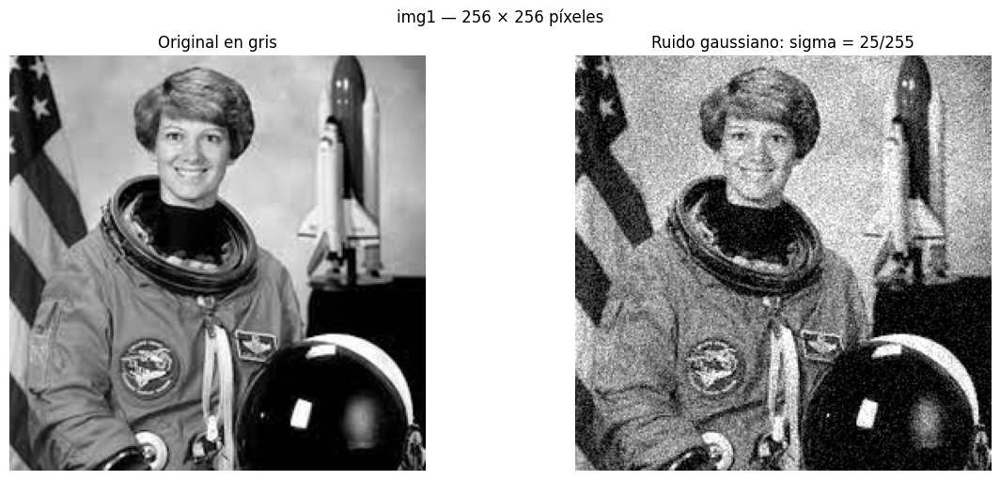

img1: referencia y ruido guardados, tamaño 256 × 256.


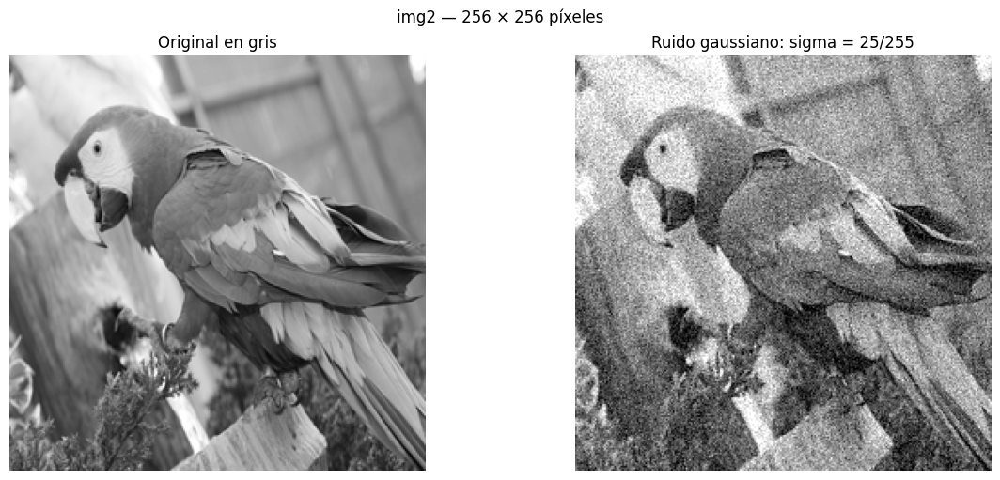

img2: referencia y ruido guardados, tamaño 256 × 256.


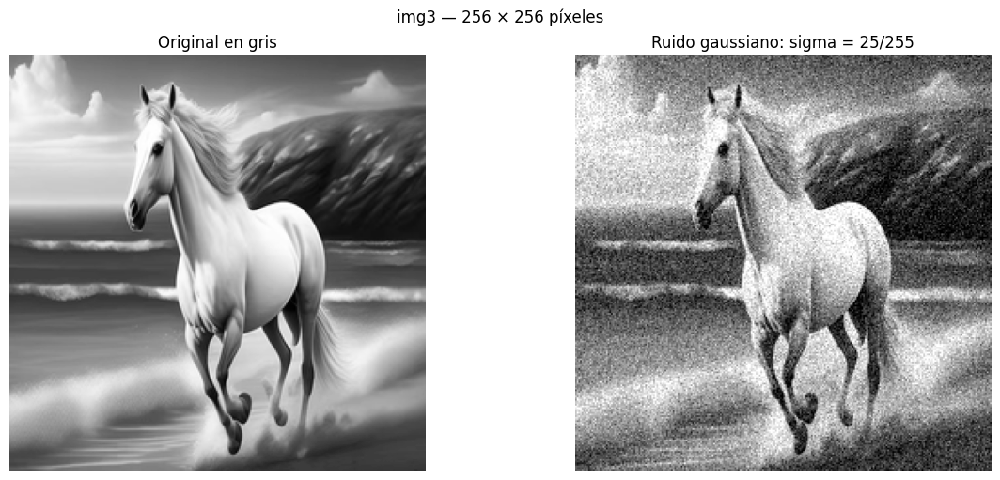

img3: referencia y ruido guardados, tamaño 256 × 256.


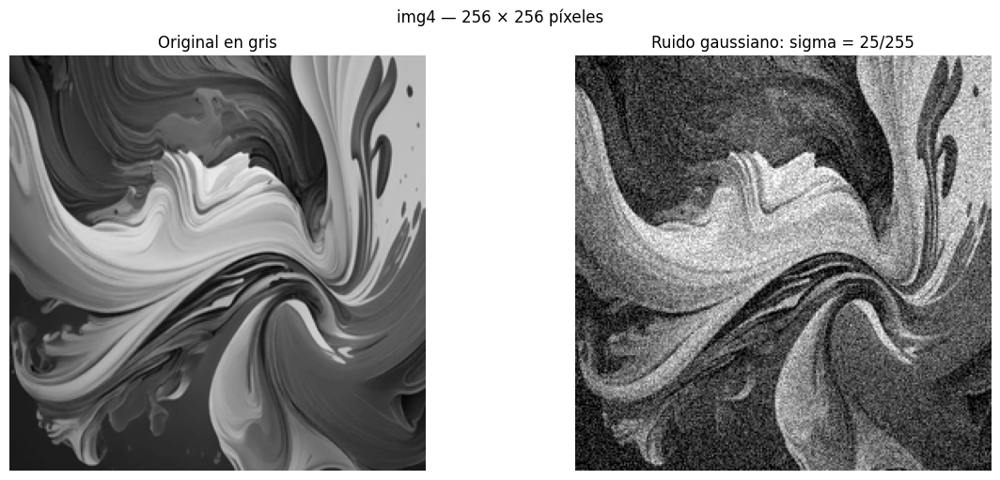

img4: referencia y ruido guardados, tamaño 256 × 256.
4b completado: 4 imágenes con ruido reproducible.
Arreglos para FFT y DnCNN: /Users/antoniopapadopolo/Library/Mobile Documents/com~apple~CloudDocs/GALILEO/CICLO 6/MATE 6/PROYECTO/final_proj_mate_6/resultados/ruido_gaussiano
Inciso 4b: PNG individuales y comparativos guardados en: /Users/antoniopapadopolo/Library/Mobile Documents/com~apple~CloudDocs/GALILEO/CICLO 6/MATE 6/PROYECTO/final_proj_mate_6/reporte/figuras/cnn/4b


In [117]:
#inciso 4b: preparar las imágenes con ruido usando la carga del notebook
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

#ruta del proyecto y carpeta para conservar los arreglos con ruido
RAIZ = CARPETA_IMAGENES.resolve().parent.parent
CARPETA_RUIDO = RAIZ / "resultados" / "ruido_gaussiano"
#se crean las carpetas de salida si no existen
CARPETA_RUIDO.mkdir(parents=True, exist_ok=True)
(CARPETA_CNN / "4b").mkdir(parents=True, exist_ok=True)
#intensidad del ruido y semilla para repetir el experimento
SIGMA = 25 / 255
SEMILLA = 42

#copias independientes: las imágenes originales del notebook se conservan
originales_4b = {}
imagenes_ruido = {}

#recorrido de las imagenes originales
for nombre, imagen in imagenes.items():
    #copia de la imagen en decimales de 32 bits
    original = np.array(imagen, dtype=np.float32, copy=True)
    #se comprueba que la imagen sea una matriz no vacia
    if original.ndim != 2 or original.size == 0:
        raise ValueError(f"{nombre}: se esperaba una imagen en gris de dos dimensiones.")
    #se verifican los valores finitos y el rango [0, 1]
    if not np.isfinite(original).all() or original.min() < 0 or original.max() > 1:
        raise ValueError(f"{nombre}: la imagen debe contener valores finitos en [0, 1].")

    #reiniciar la semilla por imagen conserva el criterio del experimento previo
    rng = np.random.default_rng(SEMILLA)
    #ruido gaussiano de media cero con el mismo tamano que la imagen
    ruido = rng.normal(0, SIGMA, original.shape).astype(np.float32)
    #se suma el ruido y se limita la imagen al rango [0, 1]
    imagen_ruidosa = np.clip(original + ruido, 0, 1)
    #se comprueba que el ruido no cambie las dimensiones ni produzca valores invalidos
    assert original.shape == imagen_ruidosa.shape
    assert np.isfinite(imagen_ruidosa).all()

    #se conservan las mismas referencias y entradas para FFT y CNN
    originales_4b[nombre] = original
    imagenes_ruido[nombre] = imagen_ruidosa
    #guardado de los arreglos originales y ruidosos para los siguientes incisos
    np.save(CARPETA_RUIDO / f"{nombre}_gris.npy", original)
    np.save(CARPETA_RUIDO / f"{nombre}_ruido_gaussiano.npy", imagen_ruidosa)
    #guardado de las imagenes individuales en la carpeta del inciso
    plt.imsave(CARPETA_CNN / "4b" / f"4b_{nombre}_original.png", original, cmap="gray", vmin=0, vmax=1)
    plt.imsave(CARPETA_CNN / "4b" / f"4b_{nombre}_ruido_gaussiano.png", imagen_ruidosa, cmap="gray", vmin=0, vmax=1)

    #dimensiones de la imagen para el titulo de la figura
    alto, ancho = original.shape
    #figura que compara la imagen original con la imagen ruidosa
    fig, ejes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    #se muestran ambas imagenes con la misma escala de intensidades
    for eje, datos, titulo in zip(
        ejes, (original, imagen_ruidosa),
        ("Original en gris", "Ruido gaussiano: sigma = 25/255")
    ):
        eje.imshow(datos, cmap="gray", vmin=0, vmax=1, aspect="equal")
        eje.set_title(titulo)
        eje.axis("off")
    #titulo y guardado de la figura comparativa
    fig.suptitle(f"{nombre} — {ancho} × {alto} píxeles")
    fig.savefig(CARPETA_CNN / "4b" / f"4b_{nombre}_ruido_gaussiano_comparacion.png",
                dpi=150, bbox_inches="tight")
    #se muestra la figura y se cierra para liberar memoria
    plt.show()
    plt.close(fig)
    #mensaje de procesamiento de la imagen actual
    print(f"{nombre}: referencia y ruido guardados, tamaño {ancho} × {alto}.")

#resumen del inciso y ubicacion de los archivos guardados
print(f"4b completado: {len(imagenes_ruido)} imágenes con ruido reproducible.")
print(f"Arreglos para FFT y DnCNN: {CARPETA_RUIDO}")
print(f"Inciso 4b: PNG individuales y comparativos guardados en: {(CARPETA_CNN / '4b').resolve()}")


## Inciso 4c. Limpieza con los filtros de FFT
Aplique los filtros de FFT implementados para intentar limpiar la imagen.


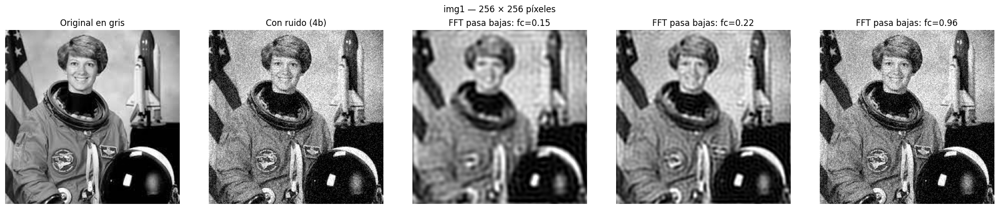

img1: filtros aplicados sin generar ruido nuevo ni redimensionar.


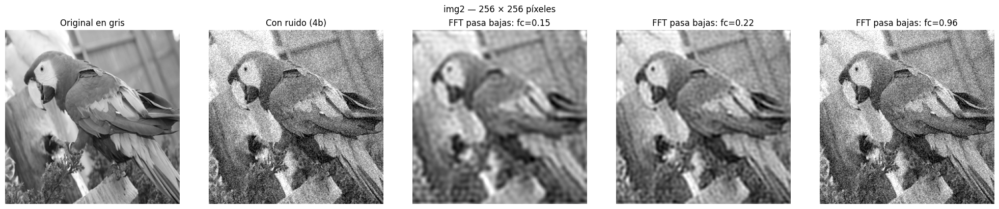

img2: filtros aplicados sin generar ruido nuevo ni redimensionar.


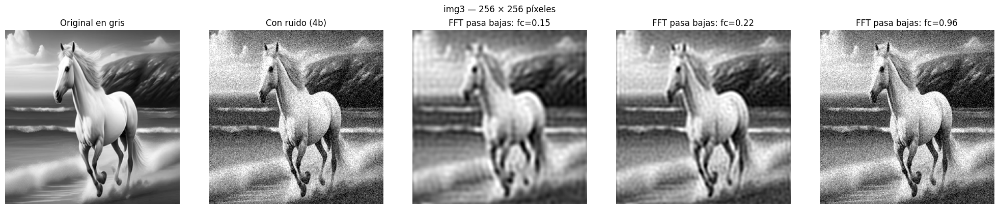

img3: filtros aplicados sin generar ruido nuevo ni redimensionar.


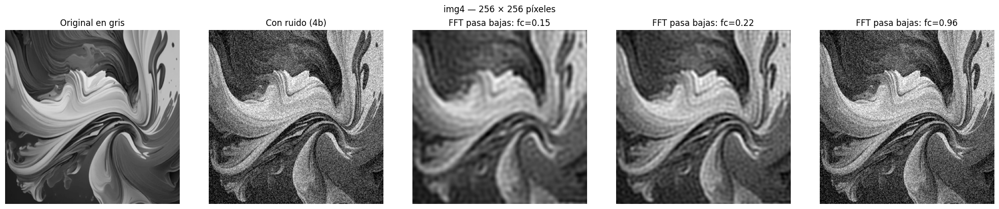

img4: filtros aplicados sin generar ruido nuevo ni redimensionar.
Resultados FFT guardados en: /Users/antoniopapadopolo/Library/Mobile Documents/com~apple~CloudDocs/GALILEO/CICLO 6/MATE 6/PROYECTO/final_proj_mate_6/resultados/fft
Inciso 4c: PNG individuales y comparativos guardados en: /Users/antoniopapadopolo/Library/Mobile Documents/com~apple~CloudDocs/GALILEO/CICLO 6/MATE 6/PROYECTO/final_proj_mate_6/reporte/figuras/cnn/4c


In [118]:
#tODO: limpiar img_ruido con filtro_pasabajas y varios fc
#inciso 4c: limpiar las entradas de 4b con la FFT de Tony
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

#ruta del proyecto para importar el nucleo de FFT
RAIZ = CARPETA_IMAGENES.resolve().parent.parent
#se agrega la carpeta del nucleo si todavia no esta en las rutas de importacion
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

#funciones de filtrado y comprobacion de dimensiones del nucleo
pass  # importacion omitida: el nucleo ya esta incluido arriba

#carpetas de entrada y salida de los resultados FFT
CARPETA_RUIDO = RAIZ / "resultados" / "ruido_gaussiano"
CARPETA_FFT = RAIZ / "resultados" / "fft"
#frecuencias de corte que se prueban con el filtro pasa bajas
FC_4C = (0.15, 0.22, 0.96)

#se comprueba que la carga de imagenes ya se haya ejecutado
if "imagenes" not in globals() or not imagenes:
    raise RuntimeError("Ejecuta primero la sección de carga de imágenes.")

#comprobar que estén todas las entradas guardadas en 4b
for nombre in imagenes:
    #se buscan tanto la referencia como la entrada ruidosa de cada imagen
    for sufijo in ("gris", "ruido_gaussiano"):
        ruta = CARPETA_RUIDO / f"{nombre}_{sufijo}.npy"
        #si falta una entrada se solicita ejecutar el inciso 4b
        if not ruta.is_file():
            raise FileNotFoundError(f"Falta {ruta}. Ejecuta primero 4b.")

#se crean las carpetas de salida si no existen
CARPETA_FFT.mkdir(parents=True, exist_ok=True)
(CARPETA_CNN / "4c").mkdir(parents=True, exist_ok=True)
#diccionario para conservar los resultados de cada frecuencia de corte
resultados_fft_4c = {}

#recorrido de las imagenes del proyecto
for nombre in imagenes:
    #carga de la referencia y de la imagen con el ruido guardado en 4b
    original = np.load(
        CARPETA_RUIDO / f"{nombre}_gris.npy",
        allow_pickle=False
    )
    ruidosa = np.load(
        CARPETA_RUIDO / f"{nombre}_ruido_gaussiano.npy",
        allow_pickle=False
    )

    #se comprueba que ambas entradas sean matrices del mismo tamano
    if original.ndim != 2 or original.shape != ruidosa.shape:
        raise ValueError(
            f"{nombre}: las entradas deben ser imágenes 2D del mismo tamaño."
        )
    #la FFT recursiva requiere dimensiones que sean potencias de 2
    if not all(es_potencia_de_2(n) for n in ruidosa.shape):
        raise ValueError(
            f"{nombre}: la FFT requiere dimensiones potencia de 2. Repite 4b."
        )
    #se verifican los valores finitos y el rango [0, 1] de las entradas
    for datos in (original, ruidosa):
        if not np.isfinite(datos).all() or datos.min() < 0 or datos.max() > 1:
            raise ValueError(f"{nombre}: se requieren valores finitos en [0, 1].")

    #se preparan las salidas y los paneles de comparacion de esta imagen
    resultados_fft_4c[nombre] = {}
    paneles = [original, ruidosa]
    titulos = ["Original en gris", "Con ruido (4b)"]
    #guardado de la referencia y la entrada ruidosa como PNG individuales
    plt.imsave(CARPETA_CNN / "4c" / f"4c_{nombre}_original.png", original, cmap="gray", vmin=0, vmax=1)
    plt.imsave(CARPETA_CNN / "4c" / f"4c_{nombre}_ruido_gaussiano.png", ruidosa, cmap="gray", vmin=0, vmax=1)

    #se aplica el filtro a la misma entrada con cada frecuencia de corte
    for fc in FC_4C:
        #usa la FFT propia de Tony y limita la salida a [0, 1]
        resultado = filtro_pasabajas(ruidosa, fc, tipo="ideal")

        #se verifica que el filtro conserve el tamano y produzca valores finitos
        if resultado.shape != original.shape or not np.isfinite(resultado).all():
            raise RuntimeError(f"Salida inválida para {nombre}, fc={fc}.")

        #se conserva la salida y se guarda el PNG de cada corte
        resultados_fft_4c[nombre][fc] = resultado
        plt.imsave(CARPETA_CNN / "4c" / f"4c_{nombre}_fft_fc_{fc:.2f}.png", resultado, cmap="gray", vmin=0, vmax=1)
        #guardado del arreglo numerico para calcular las metricas del inciso 5
        np.save(
            CARPETA_FFT / f"{nombre}_restaurada_fft_fc_{fc:.2f}.npy",
            resultado
        )
        #se agrega la salida y su titulo a la comparacion
        paneles.append(resultado)
        titulos.append(f"FFT pasa bajas: fc={fc}")

    #figura con la referencia, la entrada ruidosa y los tres resultados FFT
    fig, ejes = plt.subplots(
        1, len(paneles), figsize=(20, 4), constrained_layout=True
    )
    #se muestra cada panel con la misma escala de grises
    for eje, datos, titulo in zip(ejes, paneles, titulos):
        eje.imshow(datos, cmap="gray", vmin=0, vmax=1, aspect="equal")
        eje.set_title(titulo)
        eje.axis("off")

    #dimensiones de la imagen para el titulo de la figura
    alto, ancho = original.shape
    fig.suptitle(f"{nombre} — {ancho} × {alto} píxeles")
    #guardado de la figura comparativa en la carpeta del inciso
    fig.savefig(
        CARPETA_CNN / "4c" / f"4c_{nombre}_fft_comparacion.png",
        dpi=150, bbox_inches="tight"
    )
    #se muestra la figura y se cierra para liberar memoria
    plt.show()
    plt.close(fig)

    #mensaje de procesamiento de la imagen actual
    print(f"{nombre}: filtros aplicados sin generar ruido nuevo ni redimensionar.")

#ubicacion de los arreglos y de las imagenes PNG guardadas
print(f"Resultados FFT guardados en: {CARPETA_FFT}")
print(f"Inciso 4c: PNG individuales y comparativos guardados en: {(CARPETA_CNN / '4c').resolve()}")


## Inciso 4d. Limpieza con la CNN

Aplique el filtro basado en IA a la misma imagen con ruido.


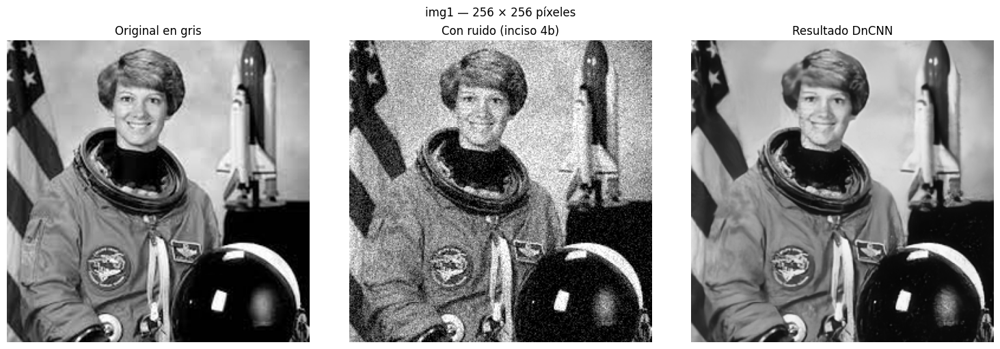

img1: DnCNN aplicada sin generar ruido nuevo ni redimensionar.


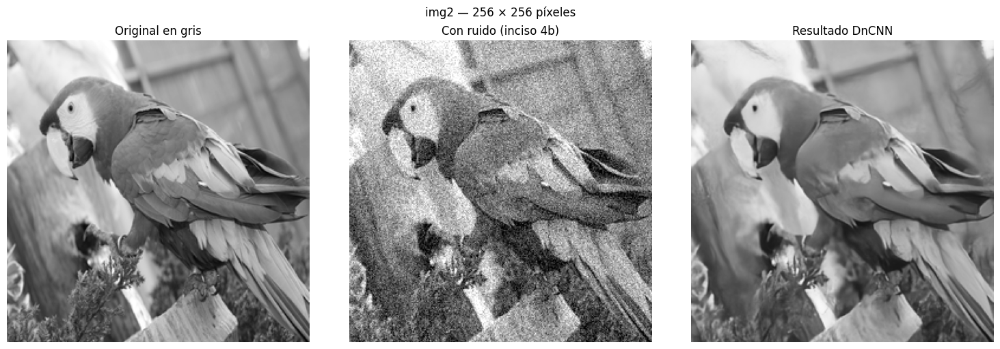

img2: DnCNN aplicada sin generar ruido nuevo ni redimensionar.


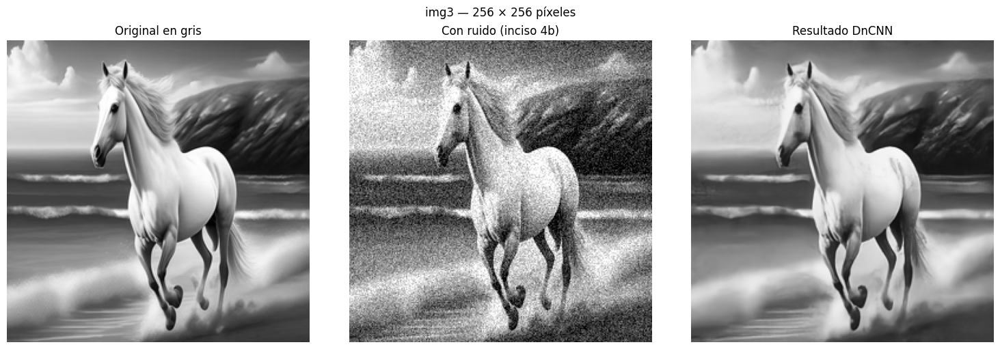

img3: DnCNN aplicada sin generar ruido nuevo ni redimensionar.


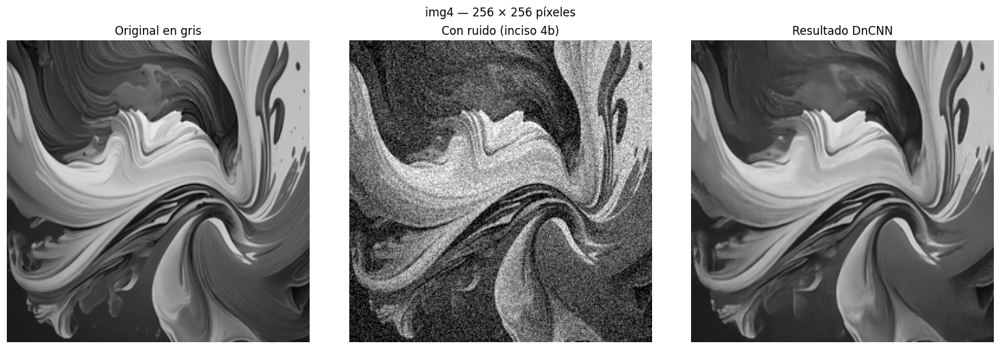

img4: DnCNN aplicada sin generar ruido nuevo ni redimensionar.


,Imagen,Ancho,Alto,Dimensiones conservadas,Entrada
0,img1,256,256,True,img1_ruido_gaussiano.npy
1,img2,256,256,True,img2_ruido_gaussiano.npy
2,img3,256,256,True,img3_ruido_gaussiano.npy
3,img4,256,256,True,img4_ruido_gaussiano.npy


4d completado: 4 imágenes. Resultados: /Users/antoniopapadopolo/Library/Mobile Documents/com~apple~CloudDocs/GALILEO/CICLO 6/MATE 6/PROYECTO/final_proj_mate_6/resultados/dncnn
Inciso 4d: PNG individuales y comparativos guardados en: /Users/antoniopapadopolo/Library/Mobile Documents/com~apple~CloudDocs/GALILEO/CICLO 6/MATE 6/PROYECTO/final_proj_mate_6/reporte/figuras/cnn/4d


In [119]:
#inciso 4d: aplicar el modelo de 4a a las entradas guardadas en 4b
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch

#se comprueba que el modelo de 4a ya este cargado
if "modelo_dncnn_4a" not in globals():
    raise RuntimeError("Ejecuta primero el inciso 4a para cargar DnCNN.")
#se comprueba que la carga de imagenes ya se haya ejecutado
if "imagenes" not in globals() or not imagenes:
    raise RuntimeError("Ejecuta primero la sección de carga de imágenes.")

#rutas del proyecto y de los arreglos de entrada y salida
RAIZ = CARPETA_IMAGENES.resolve().parent.parent
CARPETA_RUIDO = RAIZ / "resultados" / "ruido_gaussiano"
CARPETA_DNCNN = RAIZ / "resultados" / "dncnn"
#nombres de las mismas imagenes utilizadas en el inciso 4b
NOMBRES = tuple(imagenes)  #img1, img2, img3, img4: mismas claves que en 4b

#comprobar que todas las entradas existen antes de comenzar la inferencia
for nombre in NOMBRES:
    #se verifica que existan la referencia y la entrada ruidosa de cada imagen
    for sufijo in ("gris", "ruido_gaussiano"):
        ruta = CARPETA_RUIDO / f"{nombre}_{sufijo}.npy"
        #si falta una entrada se solicita ejecutar el inciso 4b
        if not ruta.is_file():
            raise FileNotFoundError(f"Falta {ruta}. Ejecuta primero el inciso 4b.")

#se crean las carpetas de salida si no existen
CARPETA_DNCNN.mkdir(parents=True, exist_ok=True)
(CARPETA_CNN / "4d").mkdir(parents=True, exist_ok=True)
#se activa el modo de evaluacion del modelo preentrenado
modelo_dncnn_4a.eval()
#se utiliza el mismo dispositivo donde estan los pesos de la red
dispositivo = next(modelo_dncnn_4a.parameters()).device
#listas y diccionarios para conservar las comprobaciones y las salidas
registros_4d = []
resultados_dncnn_4d = {}
resultados_crudos_dncnn_4d = {}

#recorrido de las mismas entradas guardadas en 4b
for nombre in NOMBRES:
    #rutas de la referencia y de la imagen ruidosa
    ruta_original = CARPETA_RUIDO / f"{nombre}_gris.npy"
    ruta_ruidosa = CARPETA_RUIDO / f"{nombre}_ruido_gaussiano.npy"
    #carga de los arreglos sin generar ruido nuevo
    original = np.load(ruta_original, allow_pickle=False)
    imagen_ruidosa = np.load(ruta_ruidosa, allow_pickle=False)
    #se comprueba que ambas imagenes sean matrices no vacias
    if original.ndim != 2 or imagen_ruidosa.ndim != 2 or original.size == 0:
        raise ValueError(f"{nombre}: las entradas deben ser imágenes en gris no vacías.")
    #se comprueba que las dimensiones de ambas entradas coincidan
    if original.shape != imagen_ruidosa.shape:
        raise ValueError(f"{nombre}: las dimensiones de las entradas de 4b no coinciden.")
    #se verifican los valores finitos y el rango [0, 1]
    for datos in (original, imagen_ruidosa):
        if not np.isfinite(datos).all() or datos.min() < 0 or datos.max() > 1:
            raise ValueError(f"{nombre}: se requieren valores finitos en [0, 1].")

    #conversion de la imagen ruidosa a un tensor de PyTorch
    entrada = torch.from_numpy(np.ascontiguousarray(imagen_ruidosa, dtype=np.float32))
    #se agregan los ejes de lote y canal y se envia al dispositivo
    entrada = entrada[None, None].to(dispositivo)
    #se aplica la red sin entrenamiento ni calculo de gradientes
    with torch.inference_mode():
        salida = modelo_dncnn_4a(entrada)
    #se comprueba que la salida tenga el mismo tamano y valores finitos
    if salida.shape != entrada.shape or not torch.isfinite(salida).all().item():
        raise RuntimeError(f"{nombre}: DnCNN produjo dimensiones o valores inválidos.")

    #se usa el modelo directamente para conservar también la salida sin recorte
    salida_cruda = salida[0, 0].cpu().numpy()
    #se limita la salida restaurada al rango valido [0, 1]
    resultado = np.clip(salida_cruda, 0, 1)
    #guardado de la salida cruda y la salida restaurada como arreglos
    np.save(CARPETA_DNCNN / f"{nombre}_salida_cruda_dncnn.npy", salida_cruda)
    np.save(CARPETA_DNCNN / f"{nombre}_restaurada_dncnn.npy", resultado)
    #se conservan ambas salidas para la comparacion posterior
    resultados_crudos_dncnn_4d[nombre] = salida_cruda
    resultados_dncnn_4d[nombre] = resultado
    #guardado de la referencia, la entrada ruidosa y el resultado como PNG individuales
    plt.imsave(CARPETA_CNN / "4d" / f"4d_{nombre}_original.png", original, cmap="gray", vmin=0, vmax=1)
    plt.imsave(CARPETA_CNN / "4d" / f"4d_{nombre}_ruido_gaussiano.png", imagen_ruidosa, cmap="gray", vmin=0, vmax=1)
    plt.imsave(CARPETA_CNN / "4d" / f"4d_{nombre}_dncnn.png", resultado, cmap="gray", vmin=0, vmax=1)

    #dimensiones de la imagen para preparar la comparacion
    alto, ancho = original.shape
    #figura con la referencia, la imagen ruidosa y la salida de DnCNN
    fig, ejes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
    #se muestran los tres paneles con la misma escala de grises
    for eje, datos, titulo in zip(
        ejes, (original, imagen_ruidosa, resultado),
        ("Original en gris", "Con ruido (inciso 4b)", "Resultado DnCNN")
    ):
        eje.imshow(datos, cmap="gray", vmin=0, vmax=1, aspect="equal")
        eje.set_title(titulo)
        eje.axis("off")
    #titulo y guardado de la figura comparativa
    fig.suptitle(f"{nombre} — {ancho} × {alto} píxeles")
    fig.savefig(CARPETA_CNN / "4d" / f"4d_{nombre}_dncnn_comparacion.png", dpi=150, bbox_inches="tight")
    #se muestra la figura y se cierra para liberar memoria
    plt.show()
    plt.close(fig)
    #registro del tamano de la salida y del archivo de entrada utilizado
    registros_4d.append({
        "Imagen": nombre, "Ancho": ancho, "Alto": alto,
        "Dimensiones conservadas": resultado.shape == original.shape,
        "Entrada": ruta_ruidosa.name,
    })
    #mensaje de procesamiento de la imagen actual
    print(f"{nombre}: DnCNN aplicada sin generar ruido nuevo ni redimensionar.")

#tabla con las comprobaciones de todas las imagenes procesadas
tabla_4d = pd.DataFrame(registros_4d)
#se muestra el resumen de procesamiento
display(tabla_4d)
#guardado de la tabla y mensajes con la ubicacion de los resultados
tabla_4d.to_csv(CARPETA_DNCNN / "resumen_4d.csv", index=False)
print(f"4d completado: {len(resultados_dncnn_4d)} imágenes. Resultados: {CARPETA_DNCNN}")
print(f"Inciso 4d: PNG individuales y comparativos guardados en: {(CARPETA_CNN / '4d').resolve()}")


## Inciso 5. Comparación con MSE, PSNR y SSIM

¿Cuál filtro funcionó mejor? Justifique su respuesta mostrando las imágenes resultantes y
explicando brevemente cómo la IA puede superar a los filtros clásicos en ciertas tareas al
"aprender" las características de una imagen limpia.


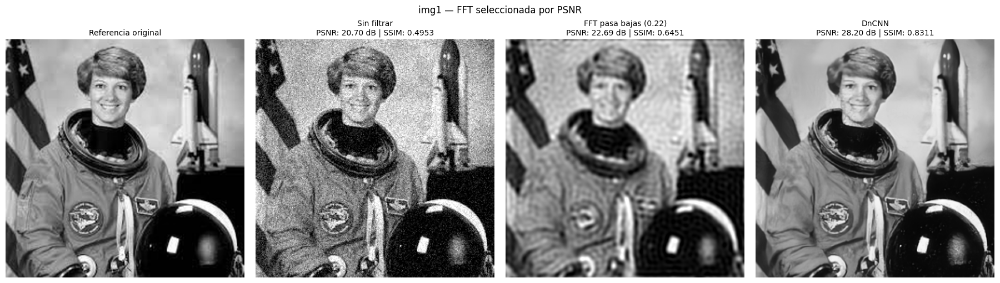

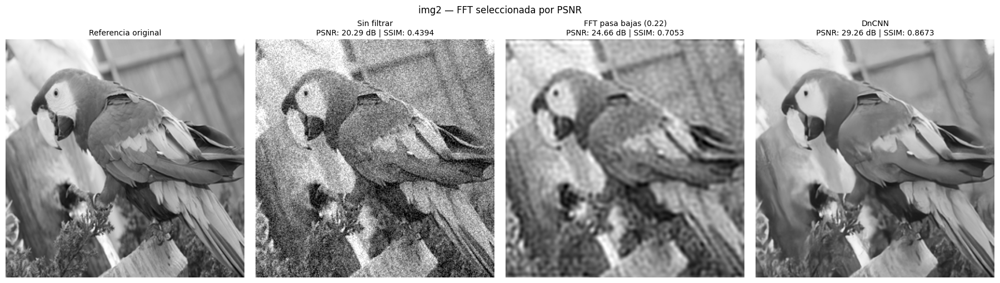

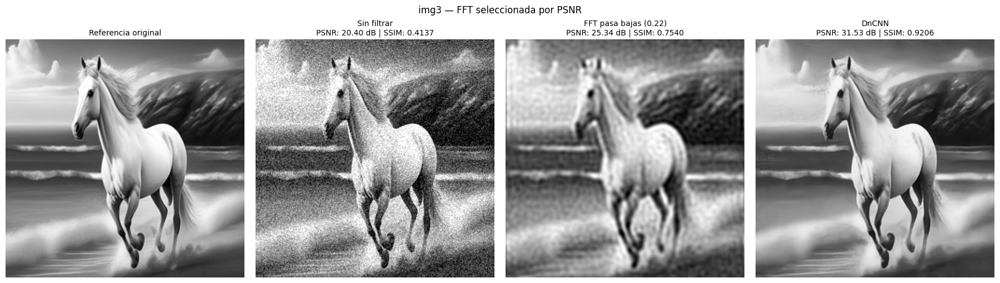

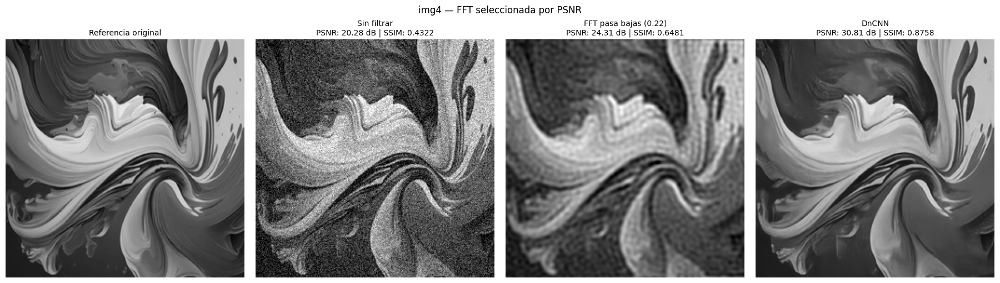

**Resultados por imagen:** menor MSE y mayores PSNR y SSIM indican mayor similitud con la referencia.

,Imagen,Método,MSE,PSNR (dB),SSIM
0,img1,Sin filtrar,0.008518,20.70,0.4953
1,img1,FFT pasa bajas (0.15),0.007998,20.97,0.5603
2,img1,FFT pasa bajas (0.22),0.005381,22.69,0.6451
3,img1,FFT pasa bajas (0.96),0.008479,20.72,0.4958
4,img1,DnCNN,0.001513,28.20,0.8311
5,img2,Sin filtrar,0.009362,20.29,0.4394
6,img2,FFT pasa bajas (0.15),0.004568,23.40,0.6461
7,img2,FFT pasa bajas (0.22),0.003418,24.66,0.7053
8,img2,FFT pasa bajas (0.96),0.009324,20.30,0.4401
9,img2,DnCNN,0.001187,29.26,0.8673


,Imagen,Mejor FFT por PSNR,PSNR ruido,PSNR FFT,PSNR DnCNN,Mayor PSNR (CNN vs FFT),Mejor FFT por SSIM,SSIM ruido,SSIM FFT,SSIM DnCNN,Mayor SSIM (CNN vs FFT)
0,img1,FFT pasa bajas (0.22),20.6968,22.6913,28.2026,DnCNN,FFT pasa bajas (0.22),0.4953,0.6451,0.8311,DnCNN
1,img2,FFT pasa bajas (0.22),20.2862,24.6623,29.2563,DnCNN,FFT pasa bajas (0.22),0.4394,0.7053,0.8673,DnCNN
2,img3,FFT pasa bajas (0.22),20.3968,25.3422,31.5288,DnCNN,FFT pasa bajas (0.22),0.4137,0.7540,0.9206,DnCNN
3,img4,FFT pasa bajas (0.22),20.2766,24.3139,30.8076,DnCNN,FFT pasa bajas (0.22),0.4322,0.6481,0.8758,DnCNN


**Promedios por método** (PSNR: media de los valores en dB):

,MSE,PSNR (dB),SSIM
Método,,,
Sin filtrar,0.009097,20.41,0.4452
FFT pasa bajas (0.15),0.005433,22.80,0.6271
FFT pasa bajas (0.22),0.003856,24.25,0.6881
FFT pasa bajas (0.96),0.009058,20.43,0.4458
DnCNN,0.001058,29.95,0.8737


DnCNN superó a la mejor FFT probada por PSNR en **4 de 4 imágenes**, con 0 empates; por SSIM, superó a la mejor FFT de esa métrica en **4 de 4 imágenes**, con 0 empates.

El filtro pasa bajas reduce componentes de alta frecuencia que contienen ruido, pero también puede eliminar bordes y texturas. DnCNN utiliza características aprendidas durante su entrenamiento para estimar el ruido y puede conservar mejor esos detalles. Esto explica por qué puede superar al filtro clásico, sin garantizarlo para todas las imágenes.

La mejor FFT se seleccionó usando la referencia original y por separado para cada métrica. Esta selección es retrospectiva entre los tres cortes probados y no es una regla para imágenes nuevas. Las figuras muestran la FFT elegida por PSNR, que puede diferir de la elegida por SSIM.

Tablas y conclusión guardadas en: /Users/antoniopapadopolo/Library/Mobile Documents/com~apple~CloudDocs/GALILEO/CICLO 6/MATE 6/PROYECTO/final_proj_mate_6/resultados/comparacion
Inciso 5: PNG individuales y comparativos guardados en: /Users/antoniopapadopolo/Library/Mobile Documents/com~apple~CloudDocs/GALILEO/CICLO 6/MATE 6/PROYECTO/final_proj_mate_6/reporte/figuras/cnn/5


In [120]:
#inciso 5: comparar las salidas de 4c y 4d contra las referencias de 4b
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
#si falta esta librería, ejecutar en otra celda: %pip install scikit-image
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio, structural_similarity

#se comprueba que la carga de imagenes ya se haya ejecutado
if "imagenes" not in globals() or not imagenes:
    raise RuntimeError("Ejecuta primero la sección de carga de imágenes.")

#rutas de las referencias, los resultados y las tablas de comparacion
RAIZ = CARPETA_IMAGENES.resolve().parent.parent
CARPETA_RUIDO = RAIZ / "resultados" / "ruido_gaussiano"
CARPETA_FFT = RAIZ / "resultados" / "fft"
CARPETA_DNCNN = RAIZ / "resultados" / "dncnn"
CARPETA_COMPARACION = RAIZ / "resultados" / "comparacion"
#frecuencias de corte que se evaluaron en el inciso 4c
FC_5 = (0.15, 0.22, 0.96)  #los tres filtros pasa bajas del inciso 4c

#comprobar los archivos antes de generar resultados parciales
for nombre in imagenes:
    #lista de entradas necesarias para comparar todos los metodos
    requeridos = [
        (CARPETA_RUIDO / f"{nombre}_gris.npy", "4b"),
        (CARPETA_RUIDO / f"{nombre}_ruido_gaussiano.npy", "4b"),
        (CARPETA_DNCNN / f"{nombre}_restaurada_dncnn.npy", "4d"),
        *[(CARPETA_FFT / f"{nombre}_restaurada_fft_fc_{fc:.2f}.npy", "4c")
          for fc in FC_5],
    ]
    #se verifica que cada archivo exista antes de iniciar la comparacion
    for ruta, inciso in requeridos:
        if not ruta.is_file():
            raise FileNotFoundError(f"Falta {ruta}. Ejecuta primero el inciso {inciso}.")

#se crean las carpetas para las tablas y las imagenes del inciso
CARPETA_COMPARACION.mkdir(parents=True, exist_ok=True)
(CARPETA_CNN / "5").mkdir(parents=True, exist_ok=True)

#funcion que calcula las metricas de cada resultado frente a la referencia
def medir_error(referencia, resultado):
    """MSE, PSNR y SSIM para imágenes en gris normalizadas a [0, 1]."""
    #conversion a decimales de 64 bits para calcular las metricas
    referencia = np.asarray(referencia, dtype=np.float64)
    resultado = np.asarray(resultado, dtype=np.float64)
    #se comprueba que las imagenes sean matrices del mismo tamano
    if referencia.ndim != 2 or referencia.shape != resultado.shape:
        raise ValueError("La referencia y el resultado deben ser imágenes 2D del mismo tamaño.")
    #SSIM necesita al menos 7 pixeles por dimension con esta configuracion
    if min(referencia.shape) < 7:
        raise ValueError("SSIM requiere al menos 7 píxeles por dimensión en esta configuración.")
    #se verifican los valores finitos y el rango [0, 1]
    for datos in (referencia, resultado):
        if not np.isfinite(datos).all() or datos.min() < 0 or datos.max() > 1:
            raise ValueError("Las imágenes deben contener valores finitos en [0, 1].")
    #error cuadratico medio: un valor menor indica mayor parecido con la referencia
    mse = float(mean_squared_error(referencia, resultado))
    #relacion senal a ruido: un valor mayor indica menor error de reconstruccion
    psnr = float("inf") if mse == 0 else float(
        peak_signal_noise_ratio(referencia, resultado, data_range=1.0)
    )
    #similitud estructural: un valor mayor indica mayor semejanza de estructura
    ssim = float(structural_similarity(referencia, resultado, data_range=1.0))
    #se devuelven las tres metricas calculadas
    return mse, psnr, ssim

#funcion que compara la CNN con la mejor FFT para una metrica
def comparar_cnn(valor_cnn, valor_fft, nombre_fft):
    #si la diferencia es menor que la tolerancia se considera un empate
    if np.isclose(valor_cnn, valor_fft, atol=1e-9, rtol=0):
        return "Empate"
    #se devuelve el metodo con el valor mas alto de PSNR o SSIM
    return "DnCNN" if valor_cnn > valor_fft else nombre_fft

#listas para construir la tabla completa y el resumen por imagen
filas_5 = []
filas_resumen_5 = []
#recorrido de las imagenes que se van a comparar
for nombre in imagenes:
    #carga de la referencia y de la entrada ruidosa del inciso 4b
    referencia = np.load(CARPETA_RUIDO / f"{nombre}_gris.npy", allow_pickle=False)
    ruidosa = np.load(CARPETA_RUIDO / f"{nombre}_ruido_gaussiano.npy", allow_pickle=False)
    #la imagen sin filtrar se incluye como punto de comparacion
    candidatos = {"Sin filtrar": ruidosa}
    #se cargan los tres resultados del filtro FFT
    for fc in FC_5:
        candidatos[f"FFT pasa bajas ({fc:.2f})"] = np.load(
            CARPETA_FFT / f"{nombre}_restaurada_fft_fc_{fc:.2f}.npy",
            allow_pickle=False
        )
    #se agrega la salida restaurada por la CNN del inciso 4d
    candidatos["DnCNN"] = np.load(
        CARPETA_DNCNN / f"{nombre}_restaurada_dncnn.npy", allow_pickle=False
    )

    #diccionario con las metricas de cada metodo para esta imagen
    puntuaciones = {}
    #se compara cada salida con la misma referencia original
    for metodo, resultado in candidatos.items():
        mse, psnr, ssim = medir_error(referencia, resultado)
        puntuaciones[metodo] = {"MSE": mse, "PSNR (dB)": psnr, "SSIM": ssim}
        #se agrega una fila con las metricas de la imagen y el metodo
        filas_5.append({"Imagen": nombre, "Método": metodo, **puntuaciones[metodo]})

    #se identifican los candidatos FFT para seleccionar los mejores resultados
    metodos_fft = [m for m in candidatos if m.startswith("FFT")]
    #se elige por separado la mejor FFT segun PSNR y segun SSIM
    mejor_fft_psnr = max(metodos_fft, key=lambda m: puntuaciones[m]["PSNR (dB)"])
    mejor_fft_ssim = max(metodos_fft, key=lambda m: puntuaciones[m]["SSIM"])
    #resumen por imagen de las metricas y los ganadores de la comparacion
    filas_resumen_5.append({
        "Imagen": nombre,
        "Mejor FFT por PSNR": mejor_fft_psnr,
        "PSNR ruido": puntuaciones["Sin filtrar"]["PSNR (dB)"],
        "PSNR FFT": puntuaciones[mejor_fft_psnr]["PSNR (dB)"],
        "PSNR DnCNN": puntuaciones["DnCNN"]["PSNR (dB)"],
        "Mayor PSNR (CNN vs FFT)": comparar_cnn(
            puntuaciones["DnCNN"]["PSNR (dB)"],
            puntuaciones[mejor_fft_psnr]["PSNR (dB)"], mejor_fft_psnr),
        "Mejor FFT por SSIM": mejor_fft_ssim,
        "SSIM ruido": puntuaciones["Sin filtrar"]["SSIM"],
        "SSIM FFT": puntuaciones[mejor_fft_ssim]["SSIM"],
        "SSIM DnCNN": puntuaciones["DnCNN"]["SSIM"],
        "Mayor SSIM (CNN vs FFT)": comparar_cnn(
            puntuaciones["DnCNN"]["SSIM"],
            puntuaciones[mejor_fft_ssim]["SSIM"], mejor_fft_ssim),
    })

    #la FFT mostrada se selecciona por PSNR; la tabla también compara por SSIM
    paneles = [("Referencia original", referencia), ("Sin filtrar", ruidosa),
               (mejor_fft_psnr, candidatos[mejor_fft_psnr]), ("DnCNN", candidatos["DnCNN"])]
    #guardado de los cuatro paneles como PNG individuales
    for etiqueta, (_, datos) in zip(("original", "ruido_gaussiano", "mejor_fft", "dncnn"), paneles):
        plt.imsave(CARPETA_CNN / "5" / f"5_{nombre}_{etiqueta}.png", datos, cmap="gray", vmin=0, vmax=1)
    #figura comparativa de la referencia, el ruido, la mejor FFT y DnCNN
    fig, ejes = plt.subplots(1, 4, figsize=(18, 5), constrained_layout=True)
    #se muestra cada panel con la misma escala de grises
    for eje, (titulo, datos) in zip(ejes, paneles):
        eje.imshow(datos, cmap="gray", vmin=0, vmax=1, aspect="equal")
        texto = titulo
        #se agregan las metricas al titulo de los resultados evaluados
        if titulo in puntuaciones:
            valores = puntuaciones[titulo]
            texto += f"\nPSNR: {valores['PSNR (dB)']:.2f} dB | SSIM: {valores['SSIM']:.4f}"
        #se coloca el titulo y se ocultan los ejes de la imagen
        eje.set_title(texto, fontsize=10)
        eje.axis("off")
    #titulo y guardado de la figura comparativa
    fig.suptitle(f"{nombre} — FFT seleccionada por PSNR")
    fig.savefig(CARPETA_CNN / "5" / f"5_{nombre}_comparacion.png", dpi=150, bbox_inches="tight")
    #se muestra la figura y se cierra para liberar memoria
    plt.show()
    plt.close(fig)

#tablas con los resultados completos y el resumen por imagen
tabla_5 = pd.DataFrame(filas_5)
resumen_5 = pd.DataFrame(filas_resumen_5)
#promedio de cada metrica para cada metodo evaluado
promedios_5 = tabla_5.groupby("Método", sort=False)[["MSE", "PSNR (dB)", "SSIM"]].mean()
#se explica como interpretar las metricas y se muestran las tablas
display(Markdown("**Resultados por imagen:** menor MSE y mayores PSNR y SSIM indican mayor similitud con la referencia."))
display(tabla_5.round({"MSE": 6, "PSNR (dB)": 2, "SSIM": 4}))
display(resumen_5.round(4))
#se muestran los promedios con decimales ajustados para facilitar la lectura
display(Markdown("**Promedios por método** (PSNR: media de los valores en dB):"))
display(promedios_5.round({"MSE": 6, "PSNR (dB)": 2, "SSIM": 4}))
#guardado de las metricas, el resumen y los promedios en archivos CSV
tabla_5.to_csv(CARPETA_COMPARACION / "metricas_5.csv", index=False)
resumen_5.to_csv(CARPETA_COMPARACION / "resumen_5.csv", index=False)
promedios_5.to_csv(CARPETA_COMPARACION / "promedios_5.csv")

#cantidad de imagenes incluidas en la comparacion
n = len(resumen_5)
#cantidad de imagenes donde DnCNN supera a la mejor FFT en cada metrica
victorias_psnr = int((resumen_5["Mayor PSNR (CNN vs FFT)"] == "DnCNN").sum())
victorias_ssim = int((resumen_5["Mayor SSIM (CNN vs FFT)"] == "DnCNN").sum())
#cantidad de empates entre DnCNN y la mejor FFT
empates_psnr = int((resumen_5["Mayor PSNR (CNN vs FFT)"] == "Empate").sum())
empates_ssim = int((resumen_5["Mayor SSIM (CNN vs FFT)"] == "Empate").sum())
#conclusion automatica basada en los resultados de esta ejecucion
conclusion_5 = (
    f"DnCNN superó a la mejor FFT probada por PSNR en **{victorias_psnr} de {n} imágenes**, "
    f"con {empates_psnr} empates; por SSIM, superó a la mejor FFT de esa métrica en "
    f"**{victorias_ssim} de {n} imágenes**, con {empates_ssim} empates.\n\n"
    "El filtro pasa bajas reduce componentes de alta frecuencia que contienen ruido, "
    "pero también puede eliminar bordes y texturas. DnCNN utiliza características aprendidas "
    "durante su entrenamiento para estimar el ruido y puede conservar mejor esos detalles. "
    "Esto explica por qué puede superar al filtro clásico, sin garantizarlo para todas las imágenes.\n\n"
    "La mejor FFT se seleccionó usando la referencia original y por separado para cada métrica. "
    "Esta selección es retrospectiva entre los tres cortes probados y no es una regla para imágenes nuevas. "
    "Las figuras muestran la FFT elegida por PSNR, que puede diferir de la elegida por SSIM."
)
#se muestra la conclusion y se guarda como texto Markdown
display(Markdown(conclusion_5))
(CARPETA_COMPARACION / "conclusion_5.md").write_text(conclusion_5, encoding="utf-8")
#mensajes con la ubicacion de las tablas, la conclusion y las imagenes PNG
print(f"Tablas y conclusión guardadas en: {CARPETA_COMPARACION}")
print(f"Inciso 5: PNG individuales y comparativos guardados en: {(CARPETA_CNN / '5').resolve()}")


### ¿Cuál filtro funcionó mejor?

En este experimento, **DnCNN fue el método que mejor recuperó las imágenes después de agregarles ruido**. Al compararlo con los tres filtros pasa bajas de FFT que probamos (cortes 0.15, 0.22 y 0.96), obtuvo el menor error cuadrático y el mayor PSNR en las cuatro imágenes. Esto significa que sus resultados quedaron más cerca de las referencias originales en escala de grises.

Los valores obtenidos en la ejecución verificada fueron los siguientes. Si cambiamos el ruido o las imágenes, debemos volver a ejecutar la comparación y actualizar este resumen.

| Imagen | Con ruido (dB) | Mejor FFT: pasa bajas 0.22 (dB) | DnCNN (dB) |
|---|---:|---:|---:|
| img1.jpeg | 20.70 | 22.69 | 28.20 |
| img2.png | 20.29 | 24.66 | 29.26 |
| img3.jpg | 20.40 | 25.34 | 31.53 |
| img4.jpg | 20.28 | 24.31 | 30.81 |

Entre las opciones FFT, el pasa bajas con frecuencia de corte 0.22 dio el mejor resultado en las cuatro imágenes. Con el corte 0.15 se eliminan más frecuencias, pero también se pierde información útil: en las cuatro imágenes quedó por debajo del corte 0.22 (en la astronauta, 20.97 dB frente a 22.69 dB) y en esa imagen apenas mejoró respecto de la entrada con ruido, que fue de 20.70 dB. Esto muestra que suavizar más una imagen no siempre significa recuperarla mejor. Por otro lado, el corte 0.96 dejó pasar casi todo el espectro y produjo muy poco cambio respecto de la entrada ruidosa (20.72 dB frente a 20.70 dB en la astronauta).

En esta comparación no se incluyeron filtros pasa altas, porque no sirven para limpiar una imagen: al quitar las frecuencias bajas eliminan el brillo medio y buena parte de la estructura suave, y conservan las frecuencias altas, donde el ruido pesa más que el contenido de la imagen. Su resultado es un mapa de bordes, como se vio en el inciso 2, y no una versión restaurada de la imagen.

### ¿Por qué puede funcionar mejor la CNN?

Un pasa bajas decide qué conservar según la frecuencia. El problema es que tanto el ruido como algunos detalles importantes pueden estar en las frecuencias altas. Por eso, cuando intentamos quitar ruido también podemos perder bordes y texturas.

DnCNN utiliza filtros cuyos valores fueron aprendidos durante un entrenamiento previo. Al combinar varias capas, puede usar patrones del entorno de cada píxel para estimar qué parte de la entrada corresponde al ruido. La red estima ese residuo y lo resta de la imagen. En nuestro trabajo no la entrenamos: cargamos los pesos publicados y los usamos para procesar las imágenes. Esta estrategia se describe en el [artículo original de DnCNN](https://arxiv.org/abs/1608.03981).

En las comparaciones se aprecia que DnCNN reduce bastante el granulado y mantiene las formas principales. Aun así, no recupera todos los detalles: en la astronauta se suavizan el rostro y partes del traje, y en las demás imágenes también pueden perderse texturas pequeñas. Una imagen visualmente más limpia no es necesariamente una copia exacta del original.

### Alcance de la conclusión

Podemos concluir que **DnCNN funcionó mejor que las configuraciones FFT evaluadas para estas cuatro imágenes y este ruido**. No significa que siempre supere a cualquier filtro clásico. Usamos ruido gaussiano de intensidad 25/255 seguido de recorte a [0, 1], una semilla fija por imagen y las mismas entradas para ambos métodos. Comparamos las salidas limitadas a [0, 1] contra las referencias.

El PSNR respalda la conclusión bajo el criterio de error cuadrático; no mide por sí solo todos los aspectos de la calidad visual. Además, elegimos la mejor FFT mirando sus resultados frente a la referencia conocida. Esa elección es válida como comparación de los cortes probados, pero no garantiza que el mismo corte sea el mejor en otros casos.
